# Лабораторна робота №5–6. Нейронна мережа і регуляризація

**Мета роботи:** реалізувати багатошарову нейронну мережу з нуля на NumPy (прямий прохід, backpropagation, SGD), перевірити правильність градієнтів чисельно, навчитися зберігати й відновлювати модель, а також дослідити, як різні методи регуляризації впливають на точність, перенавчання, мертві нейрони та розподіл ваг.

**Дані:** FashionMNIST, 10 класів, зображення 28×28, підмножина 20 000 тренувальних і 5 000 валідаційних прикладів.

**Архітектура:** 784 → 256 → 128 → 64 → 10, ReLU у прихованих шарах, Softmax на виході, categorical cross-entropy, SGD з мінібатчами, He-ініціалізація.

## 1. Імпорти, конфігурація, seed

Усі гіперпараметри зібрані в одній комірці. Усі експерименти використовують однакові підмножини даних, однакові початкові ваги й однаковий порядок мінібатчів, тож різниця між ними зумовлена лише регуляризацією (і випадковими масками там, де є Dropout).

In [1]:
import gzip
import time
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import MaxNLocator
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split

FAST_MODE = False  # True лише для швидкої перевірки, числа не для звіту

SEED = 42
np.random.seed(SEED)

N_TRAIN = 5_000 if FAST_MODE else 20_000
N_VAL = 1_000 if FAST_MODE else 5_000
DATA_DIR = Path("data")
ARTIFACTS_DIR = Path("artifacts")
DATA_DIR.mkdir(exist_ok=True)
ARTIFACTS_DIR.mkdir(exist_ok=True)

LAYER_SIZES = [784, 256, 128, 64, 10]
INIT_METHOD = "he"
LR = 0.05  # за lr = 0.1 val accuracy сильно стрибає між епохами, і порівнювати методи важче
BATCH_SIZE = 64
EPOCHS = 4 if FAST_MODE else 20
LOG_EPS = 1e-12

GRADCHECK_EPS = 1e-5
GRADCHECK_BATCH = 10

L2_VALUES = [1e-4, 1e-3, 1e-2]
L1_VALUES = [1e-5, 1e-4, 1e-3]
DROPOUT_VALUES = [0.1, 0.3, 0.5]
WEIGHT_CLIP_VALUE = 1.0
WEIGHT_CLIP_TIGHT = 0.1  # додатковий контрольний запуск: показує ефект справді жорсткої межі
GRAD_CLIP_VALUES = [0.5, 1.0, 5.0]
COMBO_DROPOUT = 0.2

SPARSITY_THRESHOLD = 0.01
HIDDEN_LAYER_NAMES = [f"Прихований {i + 1}" for i in range(len(LAYER_SIZES) - 2)]

COLORS = {
    "train": "#2a78d6",
    "val": "#eb6834",
    "third": "#1baf7a",
    "ink": "#0b0b0b",
    "secondary": "#52514e",
    "muted": "#898781",
    "grid": "#e1e0d9",
    "axis": "#c3c2b7",
    "surface": "#fcfcfb",
}
plt.rcParams.update(
    {
        "figure.dpi": 100,
        "figure.facecolor": COLORS["surface"],
        "axes.facecolor": COLORS["surface"],
        "axes.edgecolor": COLORS["axis"],
        "axes.grid": True,
        "axes.axisbelow": True,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titlesize": 10,
        "axes.labelsize": 9,
        "axes.labelcolor": COLORS["secondary"],
        "axes.titlecolor": COLORS["ink"],
        "text.color": COLORS["ink"],
        "grid.color": COLORS["grid"],
        "grid.linewidth": 0.6,
        "xtick.color": COLORS["muted"],
        "ytick.color": COLORS["muted"],
        "xtick.labelsize": 8,
        "ytick.labelsize": 8,
        "legend.fontsize": 8,
        "legend.frameon": False,
        "lines.linewidth": 1.6,
    }
)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

NOTEBOOK_START = time.time()


def md(text):
    display(Markdown(text))


def pct(fraction, digits=2):
    return f"{100 * fraction:.{digits}f} %"


print(f"NumPy {np.__version__}, FAST_MODE={FAST_MODE}")
print(f"Архітектура: {LAYER_SIZES}, lr={LR}, batch_size={BATCH_SIZE}, епох={EPOCHS}, seed={SEED}")

NumPy 1.26.4, FAST_MODE=False
Архітектура: [784, 256, 128, 64, 10], lr=0.05, batch_size=64, епох=20, seed=42


## 2. Завантаження й підготовка даних

Датасет завантажується через `fetch_openml('Fashion-MNIST')`. Якщо OpenML недоступний, код бере оригінальні файли з репозиторію Zalando. Перше завантаження займає кілька хвилин, далі дані читаються з локального кешу `data/fashion_mnist_uint8.npz`.

Зображення перетворюються на вектори довжини 784, а пікселі нормалізуються до [0, 1]. Підмножини вибираються стратифіковано, тому всі класи представлені однаково.

Завантаження й підготовка: 1.0 с
Train: X=(20000, 784), y=(20000,); Val: X=(5000, 784), y=(5000,)
Діапазон пікселів: [0.0, 1.0]
Прикладів на клас у train: [2000, 2000, 2000, 2000, 2000, 2000, 2000, 2000, 2000, 2000]


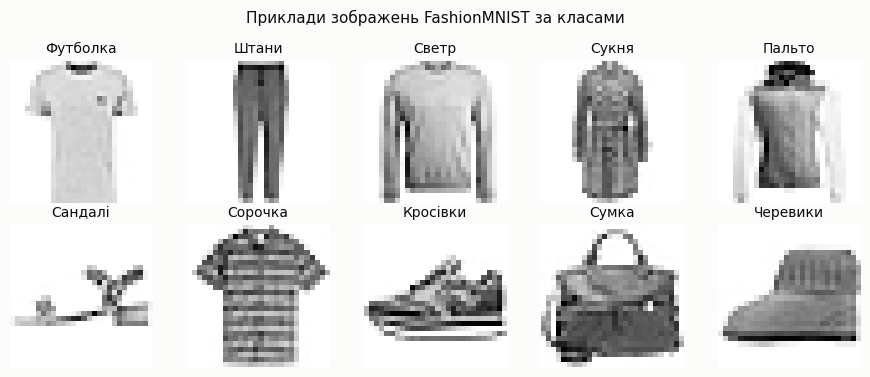

In [2]:
FASHION_URL = "https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/"


def _download_idx(file_name, header_bytes):
    """Завантажує й розпаковує один IDX-файл з репозиторію Zalando."""
    with urllib.request.urlopen(FASHION_URL + file_name, timeout=120) as response:
        raw = gzip.decompress(response.read())
    return np.frombuffer(raw, dtype=np.uint8, offset=header_bytes)


def load_fashion_mnist():
    """Повертає X (N, 784) типу uint8 і y (N,) типу int64. Використовує кеш на диску."""
    cache = DATA_DIR / "fashion_mnist_uint8.npz"
    if cache.exists():
        with np.load(cache, allow_pickle=False) as data:
            return data["X"], data["y"]

    try:
        X, y = fetch_openml(
            "Fashion-MNIST",
            version=1,
            as_frame=False,
            parser="auto",
            data_home=str(DATA_DIR),
            return_X_y=True,
        )
        X, y = X.astype(np.uint8), y.astype(np.int64)
    except Exception as error:
        print(f"OpenML недоступний ({error}), завантажую файли Zalando...")
        parts_X = [
            _download_idx(f"{prefix}-images-idx3-ubyte.gz", 16).reshape(-1, 784)
            for prefix in ("train", "t10k")
        ]
        parts_y = [_download_idx(f"{prefix}-labels-idx1-ubyte.gz", 8) for prefix in ("train", "t10k")]
        X, y = np.vstack(parts_X), np.concatenate(parts_y).astype(np.int64)

    np.savez_compressed(cache, X=X, y=y)
    return X, y


t0 = time.time()
X_all, y_all = load_fashion_mnist()
X_train, X_val, y_train, y_val = train_test_split(
    X_all, y_all, train_size=N_TRAIN, test_size=N_VAL, stratify=y_all, random_state=SEED
)
X_train = X_train.astype(np.float64) / 255.0
X_val = X_val.astype(np.float64) / 255.0
del X_all, y_all

CLASS_NAMES = ["Футболка", "Штани", "Светр", "Сукня", "Пальто", "Сандалі", "Сорочка", "Кросівки", "Сумка", "Черевики"]
print(f"Завантаження й підготовка: {time.time() - t0:.1f} с")
print(f"Train: X={X_train.shape}, y={y_train.shape}; Val: X={X_val.shape}, y={y_val.shape}")
print(f"Діапазон пікселів: [{X_train.min():.1f}, {X_train.max():.1f}]")
print(f"Прикладів на клас у train: {np.bincount(y_train).tolist()}")

fig, axes = plt.subplots(2, 5, figsize=(9, 3.8))
for class_id, ax in enumerate(axes.ravel()):
    ax.imshow(X_train[y_train == class_id][0].reshape(28, 28), cmap="Greys")
    ax.set_title(CLASS_NAMES[class_id])
    ax.axis("off")
fig.suptitle("Приклади зображень FashionMNIST за класами", fontsize=11)
fig.tight_layout()
plt.show()

## 3. Блок 1. Реалізація нейронної мережі з нуля

### Математика прямого і зворотного проходу

Позначимо `A⁽⁰⁾ = X`. Для кожного шару l:

- передактивація: `Z⁽ˡ⁾ = A⁽ˡ⁻¹⁾ W⁽ˡ⁾ + b⁽ˡ⁾`;
- активація прихованого шару: `A⁽ˡ⁾ = ReLU(Z⁽ˡ⁾)`, а за Dropout ще `A⁽ˡ⁾ ← A⁽ˡ⁾ · M⁽ˡ⁾ / (1 − p)`, де `M⁽ˡ⁾ ~ Bernoulli(1 − p)`;
- вихід: `P = Softmax(Z⁽ᴸ⁾)`.

Функція втрат `L = −(1/N) Σᵢ Σₖ Yᵢₖ log(Pᵢₖ + ε)`.

Зворотний прохід починається з `δ⁽ᴸ⁾ = ∂L/∂Z⁽ᴸ⁾ = (P − Y)/N`. Для кожного шару:

- `∇W⁽ˡ⁾ = (A⁽ˡ⁻¹⁾)ᵀ δ⁽ˡ⁾`, `∇b⁽ˡ⁾ = Σᵢ δᵢ⁽ˡ⁾`;
- `δ⁽ˡ⁻¹⁾ = (δ⁽ˡ⁾ W⁽ˡ⁾ᵀ) · M⁽ˡ⁻¹⁾/(1 − p) · 1[Z⁽ˡ⁻¹⁾ > 0]`, тобто спершу враховуємо маску Dropout, а тоді похідну ReLU.

### Один клас для всіх методів

Клас `MLP` підтримує всі методи регуляризації через параметри `l1`, `l2`, `dropout_p`, `weight_clip`, `grad_clip`, тому код не дублюється. Штрафи діють лише на ваги, зміщення `b` не штрафуються.

In [3]:
class MLP:
    """Багатошаровий перцептрон на NumPy з ручним backpropagation і SGD.

    Ваги мають форму (n_in, n_out), а передактивація шару обчислюється як Z = A @ W + b.
    Параметри регуляризації дорівнюють нулю або None, якщо метод вимкнено.
    """

    def __init__(
        self,
        layer_sizes=LAYER_SIZES,
        l1=0.0,
        l2=0.0,
        dropout_p=0.0,
        weight_clip=None,
        grad_clip=None,
        init=INIT_METHOD,
        seed=SEED,
    ):
        if not 0.0 <= dropout_p < 1.0:
            raise ValueError("dropout_p має бути в межах [0, 1)")
        if init != "he":
            raise ValueError("Підтримується лише He-ініціалізація")

        self.layer_sizes = list(layer_sizes)
        self.n_layers = len(self.layer_sizes) - 1
        self.l1, self.l2 = float(l1), float(l2)
        self.dropout_p = float(dropout_p)
        self.weight_clip = weight_clip
        self.grad_clip = grad_clip
        self.init = init
        self.seed = seed

        # Окремі генератори: маски Dropout не впливають на початкові ваги
        init_rng = np.random.default_rng(seed)
        self._dropout_rng = np.random.default_rng(seed + 1)

        self.W, self.b = [], []
        for n_in, n_out in zip(self.layer_sizes[:-1], self.layer_sizes[1:]):
            self.W.append(init_rng.normal(0.0, np.sqrt(2.0 / n_in), size=(n_in, n_out)))
            self.b.append(np.zeros(n_out))
        self.W_init = [w.copy() for w in self.W]

        self.Z, self.A, self.masks = [], [], []
        self.P = None
        self.clip_events = np.zeros(self.n_layers, dtype=np.int64)
        self.diverged = False

    @staticmethod
    def relu(z):
        return np.maximum(z, 0.0)

    @staticmethod
    def softmax(z):
        # Віднімаємо максимум у рядку перед exp, щоб уникнути переповнення
        z = z - z.max(axis=1, keepdims=True)
        exp_z = np.exp(z)
        return exp_z / exp_z.sum(axis=1, keepdims=True)

    def forward(self, X, training=False, reuse_masks=False):
        """Повертає матрицю ймовірностей і зберігає Z, A, маски для backward.

        Dropout працює лише за training=True і лише на прихованих шарах.
        reuse_masks=True повторно використовує попередні маски (потрібно для перевірки градієнтів).
        """
        use_dropout = training and self.dropout_p > 0.0
        previous_masks = self.masks
        self.Z, self.A, self.masks = [], [X], []

        activation = X
        for layer in range(self.n_layers - 1):
            z = activation @ self.W[layer] + self.b[layer]
            activation = self.relu(z)
            if use_dropout:
                if reuse_masks:
                    mask = previous_masks[layer]
                else:
                    # Нейрон залишається з імовірністю 1 − p
                    mask = self._dropout_rng.random(activation.shape) >= self.dropout_p
                activation = activation * mask / (1.0 - self.dropout_p)
                self.masks.append(mask)
            self.Z.append(z)
            self.A.append(activation)

        z_out = activation @ self.W[-1] + self.b[-1]
        self.Z.append(z_out)
        self.P = self.softmax(z_out)
        return self.P

    @staticmethod
    def cross_entropy(P, y_true):
        """Categorical cross-entropy за цілими мітками, з малим ε у логарифмі."""
        rows = np.arange(P.shape[0])
        return float(-np.mean(np.log(P[rows, y_true] + LOG_EPS)))

    def penalty(self):
        """Штраф L1 + L2 лише за вагами, без зміщень."""
        value = 0.0
        if self.l2 > 0.0:
            value += 0.5 * self.l2 * sum(np.sum(w * w) for w in self.W)
        if self.l1 > 0.0:
            value += self.l1 * sum(np.sum(np.abs(w)) for w in self.W)
        return float(value)

    def total_loss(self, P, y_true):
        return self.cross_entropy(P, y_true) + self.penalty()

    def backward(self, y_true):
        """Повертає (grads_W, grads_b), обчислені для останнього виклику forward, разом зі штрафами."""
        n_samples = self.P.shape[0]
        grads_W = [None] * self.n_layers
        grads_b = [None] * self.n_layers

        # Градієнт за виходом мережі: (P − Y) / N
        delta = self.P.copy()
        delta[np.arange(n_samples), y_true] -= 1.0
        delta /= n_samples

        for layer in reversed(range(self.n_layers)):
            grads_W[layer] = self.A[layer].T @ delta
            grads_b[layer] = delta.sum(axis=0)
            if layer > 0:
                d_activation = delta @ self.W[layer].T
                if self.masks:
                    d_activation = d_activation * self.masks[layer - 1] / (1.0 - self.dropout_p)
                delta = d_activation * (self.Z[layer - 1] > 0.0)

        # Штрафи діють лише на ваги, np.sign(0) = 0 дає субградієнт L1 у нулі
        for layer in range(self.n_layers):
            if self.l2 > 0.0:
                grads_W[layer] = grads_W[layer] + self.l2 * self.W[layer]
            if self.l1 > 0.0:
                grads_W[layer] = grads_W[layer] + self.l1 * np.sign(self.W[layer])
        return grads_W, grads_b

    @staticmethod
    def global_grad_norm(grads_W, grads_b):
        squared = sum(np.sum(g * g) for g in grads_W) + sum(np.sum(g * g) for g in grads_b)
        return float(np.sqrt(squared))

    def step(self, grads_W, grads_b, lr):
        """Робить один крок SGD. Повертає L2-норму градієнта до обрізання."""
        norm = self.global_grad_norm(grads_W, grads_b)

        scale = 1.0
        if self.grad_clip is not None and norm > 0.0:
            scale = min(1.0, self.grad_clip / norm)

        for layer in range(self.n_layers):
            self.W[layer] -= lr * scale * grads_W[layer]
            self.b[layer] -= lr * scale * grads_b[layer]
            if self.weight_clip is not None:
                self.clip_events[layer] += int(np.sum(np.abs(self.W[layer]) > self.weight_clip))
                np.clip(self.W[layer], -self.weight_clip, self.weight_clip, out=self.W[layer])
        return norm

    def evaluate(self, X, y_true, batch_size=2048):
        """Повертає (cross-entropy без штрафу, accuracy) в режимі inference."""
        total_loss, correct = 0.0, 0
        for start in range(0, X.shape[0], batch_size):
            batch_y = y_true[start : start + batch_size]
            P = self.forward(X[start : start + batch_size], training=False)
            total_loss += self.cross_entropy(P, batch_y) * batch_y.size
            correct += int(np.sum(P.argmax(axis=1) == batch_y))
        return total_loss / X.shape[0], correct / X.shape[0]

    def predict_proba(self, X, batch_size=2048):
        parts = [
            self.forward(X[start : start + batch_size], training=False).copy()
            for start in range(0, X.shape[0], batch_size)
        ]
        return np.vstack(parts)

    def fit(self, X_tr, y_tr, X_va, y_va, epochs=EPOCHS, batch_size=BATCH_SIZE, lr=LR, verbose=False):
        """Цикл навчання. Train-метрики рахуються в режимі inference, тому порівнянні між методами."""
        # Той самий seed дає той самий порядок мінібатчів у всіх експериментах
        shuffle_rng = np.random.default_rng(self.seed + 2)
        history = {
            "train_loss": [],
            "val_loss": [],
            "train_acc": [],
            "val_acc": [],
            "batch_loss": [],
            "grad_norm": [],
        }
        n_samples = X_tr.shape[0]

        for epoch in range(1, epochs + 1):
            order = shuffle_rng.permutation(n_samples)
            for start in range(0, n_samples, batch_size):
                batch = order[start : start + batch_size]
                P = self.forward(X_tr[batch], training=True)
                batch_loss = self.cross_entropy(P, y_tr[batch])
                if not np.isfinite(batch_loss):
                    self.diverged = True
                    break
                grads_W, grads_b = self.backward(y_tr[batch])
                history["batch_loss"].append(batch_loss)
                history["grad_norm"].append(self.step(grads_W, grads_b, lr))

            train_loss, train_acc = self.evaluate(X_tr, y_tr)
            val_loss, val_acc = self.evaluate(X_va, y_va)
            history["train_loss"].append(train_loss)
            history["val_loss"].append(val_loss)
            history["train_acc"].append(train_acc)
            history["val_acc"].append(val_acc)
            if verbose:
                print(
                    f"Епоха {epoch:2d}/{epochs}: "
                    f"train loss={train_loss:.4f}, acc={train_acc:.4f} | "
                    f"val loss={val_loss:.4f}, acc={val_acc:.4f}"
                )
            if self.diverged:
                print("Навчання зупинено: loss став нескінченним або NaN")
                break
        return history

    def save_weights(self, path):
        """Зберігає всі W, b, архітектуру, метод ініціалізації, seed і конфігурацію (numpy.savez)."""
        arrays = {f"W_{i}": w for i, w in enumerate(self.W)}
        arrays.update({f"b_{i}": b for i, b in enumerate(self.b)})
        np.savez(
            path,
            layer_sizes=np.array(self.layer_sizes),
            init=np.array(self.init),
            seed=np.array(self.seed),
            l1=np.array(self.l1),
            l2=np.array(self.l2),
            dropout_p=np.array(self.dropout_p),
            # None зберігаємо як NaN, бо числовий масив не може містити None
            weight_clip=np.array(np.nan if self.weight_clip is None else self.weight_clip),
            grad_clip=np.array(np.nan if self.grad_clip is None else self.grad_clip),
            **arrays,
        )

    def load_weights(self, path):
        """Завантажує ваги й конфігурацію у цей екземпляр. Архітектура має збігатися."""
        with np.load(path, allow_pickle=False) as data:
            saved_sizes = data["layer_sizes"].tolist()
            if saved_sizes != self.layer_sizes:
                raise ValueError(f"Архітектура не збігається: {saved_sizes} проти {self.layer_sizes}")
            self.W = [data[f"W_{i}"].copy() for i in range(self.n_layers)]
            self.b = [data[f"b_{i}"].copy() for i in range(self.n_layers)]
            self.init = str(data["init"])
            self.seed = int(data["seed"])
            self.l1 = float(data["l1"])
            self.l2 = float(data["l2"])
            self.dropout_p = float(data["dropout_p"])
            weight_clip, grad_clip = float(data["weight_clip"]), float(data["grad_clip"])
            self.weight_clip = None if np.isnan(weight_clip) else weight_clip
            self.grad_clip = None if np.isnan(grad_clip) else grad_clip
        return self


print("Клас MLP визначено")

Клас MLP визначено


### 3.1. Навчання базової мережі

Train-метрики рахуються в кінці кожної епохи на всій тренувальній вибірці в режимі inference. Так криві train і val можна чесно порівнювати, зокрема й для Dropout: під час навчання його маски штучно збільшують loss. `val loss` і `train loss` на графіках та в таблицях завжди означають чисту cross-entropy без штрафу, інакше моделі зі штрафом і без нього не можна було б порівнювати.

Епоха  1/20: train loss=0.5482, acc=0.8076 | val loss=0.5674, acc=0.8002


Епоха  2/20: train loss=0.5532, acc=0.7963 | val loss=0.5801, acc=0.7854


Епоха  3/20: train loss=0.5543, acc=0.7817 | val loss=0.6007, acc=0.7638


Епоха  4/20: train loss=0.4478, acc=0.8329 | val loss=0.4982, acc=0.8156


Епоха  5/20: train loss=0.4347, acc=0.8379 | val loss=0.4845, acc=0.8116


Епоха  6/20: train loss=0.3575, acc=0.8690 | val loss=0.4082, acc=0.8502


... (10 outputs left out)

Епоха 17/20: train loss=0.2331, acc=0.9123 | val loss=0.3625, acc=0.8674


Епоха 18/20: train loss=0.3020, acc=0.8882 | val loss=0.4412, acc=0.8448


Епоха 19/20: train loss=0.2799, acc=0.8975 | val loss=0.4217, acc=0.8540


Епоха 20/20: train loss=0.2107, acc=0.9212 | val loss=0.3621, acc=0.8702

Час навчання однієї моделі: 54.5 с


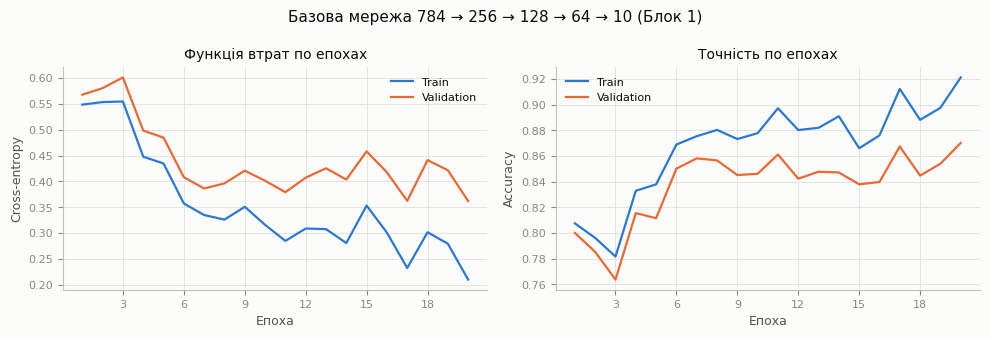

Прогноз для Блоку 2: 17 запусків, приблизно 21.6 хв


In [4]:
def plot_history(history, title):
    """Графіки loss і accuracy (train проти val) для одного запуску."""
    epochs_axis = np.arange(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
    panels = [("loss", "Cross-entropy"), ("acc", "Accuracy")]
    for ax, (key, label) in zip(axes, panels):
        ax.plot(epochs_axis, history[f"train_{key}"], color=COLORS["train"], label="Train")
        ax.plot(epochs_axis, history[f"val_{key}"], color=COLORS["val"], label="Validation")
        ax.set_xlabel("Епоха")
        ax.set_ylabel(label)
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        ax.legend()
    axes[0].set_title("Функція втрат по епохах")
    axes[1].set_title("Точність по епохах")
    fig.suptitle(title, fontsize=11)
    fig.tight_layout()
    plt.show()


t0 = time.time()
block1_model = MLP(LAYER_SIZES, seed=SEED)
block1_history = block1_model.fit(X_train, y_train, X_val, y_val, verbose=True)
block1_seconds = time.time() - t0

print(f"\nЧас навчання однієї моделі: {block1_seconds:.1f} с")
plot_history(block1_history, "Базова мережа 784 → 256 → 128 → 64 → 10 (Блок 1)")

n_planned = 1 + len(L2_VALUES) + len(L1_VALUES) + len(DROPOUT_VALUES) + 2 + len(GRAD_CLIP_VALUES) + 2
estimate_min = 1.4 * n_planned * block1_seconds / 60  # 1.4: запас на штрафи, метрики й графіки
print(f"Прогноз для Блоку 2: {n_planned} запусків, приблизно {estimate_min:.1f} хв")
if estimate_min > 30:
    print("Понад 30 хв: зменшіть EPOCHS або N_TRAIN у конфіг-комірці (див. поради на початку ноутбука)")

### 3.2. Перевірка градієнтів чисельним диференціюванням

Для вибраного параметра θ обчислюємо центральну різницю `gₙ = (L(θ + ε) − L(θ − ε)) / 2ε` і порівнюємо її з аналітичним градієнтом `gₐ` через відносну похибку

`E = |gₐ − gₙ| / max(1e-8, |gₐ| + |gₙ|)`.

**Яка похибка прийнятна** (для float64 та ε ≈ 1e-5):

| E | Оцінка |
|---|---|
| E < 1e-7 | відмінно, реалізація правильна |
| 1e-7 ≤ E < 1e-5 | прийнятно, особливо для негладких функцій |
| 1e-5 ≤ E < 1e-2 | підозріло: можливо, ε перетнув злам ReLU або L1 |
| E ≥ 1e-2 | майже напевно помилка в градієнті |

**Вибір параметрів.** Для кожного шару випадково беремо 2 ваги й 1 зміщення серед параметрів з |gₐ| > 1e-6. Параметри з майже нульовим градієнтом (наприклад, ваги від пікселів, які на цих 10 прикладах чорні) у таблицю не йдуть: там E показує лише шум округлення, а не якість реалізації. Щоб такі параметри теж не лишилися без перевірки, нижче є окрема перевірка 300 випадкових параметрів без цього фільтра за абсолютною різницею |gₐ − gₙ|.

Перевіряємо три конфігурації: без регуляризації, зі штрафами L1 + L2 і з Dropout. Для Dropout маски фіксуються, інакше L(θ + ε) і L(θ − ε) рахувалися б для різних випадкових мереж.

In [5]:
def numerical_gradient(model, X, y, param_array, index, training, eps=GRADCHECK_EPS):
    """Центральна різниця для одного елемента параметра. Значення параметра відновлюється."""
    original = param_array[index]
    param_array[index] = original + eps
    loss_plus = model.total_loss(model.forward(X, training=training, reuse_masks=training), y)
    param_array[index] = original - eps
    loss_minus = model.total_loss(model.forward(X, training=training, reuse_masks=training), y)
    param_array[index] = original
    return (loss_plus - loss_minus) / (2.0 * eps)


def relative_error(ga, gn):
    return abs(ga - gn) / max(1e-8, abs(ga) + abs(gn))


def gradient_check(model, X, y, training=False, seed=SEED):
    """Порівнює аналітичні й чисельні градієнти. Повертає (таблиця, max абс. різниця без фільтра)."""
    rng = np.random.default_rng(seed)
    # Перший forward створює маски, якщо ввімкнено Dropout. Далі вони лише повторюються
    model.forward(X, training=training)
    grads_W, grads_b = model.backward(y)

    rows = []
    for layer in range(model.n_layers):
        for kind, params, grads, count in (("W", model.W, grads_W, 2), ("b", model.b, grads_b, 1)):
            candidates = np.argwhere(np.abs(grads[layer]) > 1e-6)
            chosen = rng.choice(len(candidates), size=min(count, len(candidates)), replace=False)
            for position in chosen:
                index = tuple(int(v) for v in candidates[position])
                ga = float(grads[layer][index])
                gn = numerical_gradient(model, X, y, params[layer], index, training)
                rows.append(
                    {
                        "Шар": layer + 1,
                        "Параметр": kind,
                        "Індекс": str(index),
                        "Аналітичний": ga,
                        "Чисельний": gn,
                        "Відносна похибка E": relative_error(ga, gn),
                    }
                )

    # Перевірка без фільтра: випадкові параметри, зокрема й з нульовим градієнтом
    max_abs_diff = 0.0
    for _ in range(300):
        layer = int(rng.integers(model.n_layers))
        params, grads = (model.W, grads_W) if rng.random() < 0.8 else (model.b, grads_b)
        index = tuple(int(rng.integers(size)) for size in params[layer].shape)
        gn = numerical_gradient(model, X, y, params[layer], index, training)
        max_abs_diff = max(max_abs_diff, abs(float(grads[layer][index]) - gn))
    return pd.DataFrame(rows), max_abs_diff


X_check, y_check = X_train[:GRADCHECK_BATCH], y_train[:GRADCHECK_BATCH]
gradcheck_configs = [
    ("Без регуляризації", {}, False),
    ("L1 + L2 (λ1 = 1e-4, λ2 = 1e-3)", {"l1": 1e-4, "l2": 1e-3}, False),
    ("Dropout p = 0.3 (фіксовані маски)", {"dropout_p": 0.3}, True),
]

gradcheck_tables = {}
for title, params, training in gradcheck_configs:
    table, max_diff = gradient_check(MLP(LAYER_SIZES, seed=SEED, **params), X_check, y_check, training)
    gradcheck_tables[title] = table
    print(f"\n{title}")
    print(f"  max E у таблиці: {table['Відносна похибка E'].max():.2e}")
    print(f"  max |gₐ − gₙ| на 300 випадкових параметрах без фільтра: {max_diff:.2e}")
    display(table.style.format({"Аналітичний": "{:.6e}", "Чисельний": "{:.6e}", "Відносна похибка E": "{:.2e}"}))

worst_error = max(table["Відносна похибка E"].max() for table in gradcheck_tables.values())
if worst_error < 1e-7:
    verdict = "це відмінний результат: аналітичні градієнти збігаються з чисельними"
elif worst_error < 1e-5:
    verdict = "це прийнятний результат для негладкої мережі з ReLU"
elif worst_error < 1e-2:
    verdict = "значення підозріле, варто перевірити, чи ε не перетнув злам ReLU або L1"
else:
    verdict = "значення завелике, у реалізації градієнта, ймовірно, є помилка"
md(f"**Результат перевірки.** Найбільша відносна похибка серед усіх конфігурацій: E = {worst_error:.2e}, {verdict}.")


Без регуляризації
  max E у таблиці: 6.16e-07
  max |gₐ − gₙ| на 300 випадкових параметрах без фільтра: 3.60e-11


,Шар,Параметр,Індекс,Аналітичний,Чисельний,Відносна похибка E
0,1,W,"(100, 87)",-8.735161e-03,-8.735161e-03,5.37e-10
1,1,W,"(597, 117)",-2.132912e-02,-2.132912e-02,8.47e-12
2,1,b,"(112,)",3.238252e-03,3.238252e-03,4.64e-09
3,2,W,"(221, 35)",-3.711872e-04,-3.711871e-04,1.05e-08
4,2,W,"(108, 109)",4.749076e-03,4.749076e-03,4.68e-11
5,2,b,"(94,)",1.728828e-03,1.728828e-03,3.03e-09
6,3,W,"(25, 13)",2.777362e-04,2.777361e-04,6.19e-08
7,3,W,"(11, 40)",-4.470951e-03,-4.470951e-03,1.78e-09
8,3,b,"(58,)",1.188825e-02,1.188825e-02,8.91e-10
9,4,W,"(44, 5)",-3.046941e-05,-3.046945e-05,6.16e-07



L1 + L2 (λ1 = 1e-4, λ2 = 1e-3)
  max E у таблиці: 6.42e-08
  max |gₐ − gₙ| на 300 випадкових параметрах без фільтра: 6.35e-11


,Шар,Параметр,Індекс,Аналітичний,Чисельний,Відносна похибка E
0,1,W,"(69, 252)",-3.299838e-03,-3.299838e-03,1.70e-09
1,1,W,"(606, 200)",2.408344e-02,2.408344e-02,2.07e-10
2,1,b,"(112,)",3.238252e-03,3.238252e-03,1.21e-09
3,2,W,"(219, 100)",-1.433841e-03,-1.433841e-03,1.04e-08
4,2,W,"(110, 108)",-5.144372e-04,-5.144373e-04,6.42e-08
5,2,b,"(94,)",1.728828e-03,1.728828e-03,3.40e-09
6,3,W,"(25, 50)",8.089067e-02,8.089067e-02,1.21e-10
7,3,W,"(12, 3)",-2.019534e-04,-2.019533e-04,6.38e-08
8,3,b,"(58,)",1.188825e-02,1.188825e-02,8.91e-10
9,4,W,"(47, 0)",6.429648e-03,6.429648e-03,1.15e-09



Dropout p = 0.3 (фіксовані маски)
  max E у таблиці: 1.69e-08
  max |gₐ − gₙ| на 300 випадкових параметрах без фільтра: 4.91e-11


,Шар,Параметр,Індекс,Аналітичний,Чисельний,Відносна похибка E
0,1,W,"(102, 108)",9.818491e-04,9.818491e-04,1.69e-08
1,1,W,"(593, 235)",2.684994e-02,2.684994e-02,2.72e-10
2,1,b,"(112,)",2.186140e-02,2.186140e-02,7.17e-11
3,2,W,"(222, 2)",-8.585193e-03,-8.585193e-03,4.89e-10
4,2,W,"(109, 42)",4.483747e-02,4.483747e-02,1.15e-10
5,2,b,"(90,)",6.715094e-03,6.715094e-03,1.07e-09
6,3,W,"(25, 21)",9.709350e-03,9.709350e-03,3.10e-10
7,3,W,"(11, 32)",-1.230725e-02,-1.230725e-02,5.29e-10
8,3,b,"(61,)",2.231792e-02,2.231792e-02,3.22e-10
9,4,W,"(46, 3)",-3.297704e-02,-3.297704e-02,4.49e-10


**Результат перевірки.** Найбільша відносна похибка серед усіх конфігурацій: E = 6.16e-07, це прийнятний результат для негладкої мережі з ReLU.

### 3.3. Збереження й відновлення моделі

Сценарій перевірки: навчена мережа → `save_weights` → нова мережа з **іншим** seed (щоб її ваги спершу справді відрізнялися) → `load_weights` → подаємо однакові дані обом мережам.

In [6]:
weights_path = ARTIFACTS_DIR / "mlp_base.npz"
block1_model.save_weights(weights_path)
print(f"Збережено: {weights_path} ({weights_path.stat().st_size / 1e6:.2f} МБ)")

restored_model = MLP(LAYER_SIZES, seed=SEED + 1000)
P_original = block1_model.predict_proba(X_val)
difference_before = np.max(np.abs(P_original - restored_model.predict_proba(X_val)))

restored_model.load_weights(weights_path)
P_restored = restored_model.predict_proba(X_val)
difference_after = np.max(np.abs(P_original - P_restored))
same_classes = np.array_equal(P_original.argmax(axis=1), P_restored.argmax(axis=1))

print(f"max|P_original − P_restored| до завантаження:     {difference_before:.2e}")
print(f"max|P_original − P_restored| після завантаження: {difference_after:.2e}")
print(f"Передбачені класи збігаються: {same_classes}")
print(f"Відновлена конфігурація: seed={restored_model.seed}, init={restored_model.init}, шари={restored_model.layer_sizes}")

assert difference_after < 1e-7, "Відновлена мережа дає інші ймовірності"
assert same_classes, "Відновлена мережа дає інші класи"
print("Перевірку пройдено: різниця менша за 1e-7, класи однакові")

Збережено: artifacts\mlp_base.npz (1.95 МБ)
max|P_original − P_restored| до завантаження:     9.94e-01
max|P_original − P_restored| після завантаження: 0.00e+00
Передбачені класи збігаються: True
Відновлена конфігурація: seed=42, init=he, шари=[784, 256, 128, 64, 10]
Перевірку пройдено: різниця менша за 1e-7, класи однакові


## 4. Блок 2. Дослідження регуляризації

### 4.0. Функції метрик

- **Мертвий нейрон:** максимум його передактивації Z за всіма об'єктами тренувальної вибірки ≤ 0, тобто нейрон не активується на жодному об'єкті. Рахується в режимі inference.
- **Частка неактивних активацій:** яка частка пар «нейрон-об'єкт» має Z ≤ 0. Це додаткова метрика: неактивність на окремому об'єкті є нормальною рисою ReLU і не означає, що нейрон мертвий.
- **Sparsity:** відсоток ваг з |W| < 0.01. Важливо, що після He-ініціалізації цей показник уже ненульовий (передусім у першому шарі, де розкид ваг найменший), тому метрику слід порівнювати з початковим рівнем, а не з нулем.
- **Гістограми ваг:** ширина стовпчика 0.02, тож центральний стовпчик точно відповідає |W| < 0.01. Вісь Y логарифмічна й показує відсоток ваг шару. Сіра лінія показує початковий He-розподіл. Осі однакові в усіх панелях одного рисунка.

In [7]:
RUNS = {}


def dead_neuron_table(model, X, batch_size=2048):
    """Мертві нейрони кожного прихованого шару за всією вибіркою в режимі inference."""
    n_hidden = model.n_layers - 1
    max_z = [np.full(model.layer_sizes[i + 1], -np.inf) for i in range(n_hidden)]
    inactive = np.zeros(n_hidden)
    for start in range(0, X.shape[0], batch_size):
        model.forward(X[start : start + batch_size], training=False)
        for layer in range(n_hidden):
            max_z[layer] = np.maximum(max_z[layer], model.Z[layer].max(axis=0))
            inactive[layer] += np.sum(model.Z[layer] <= 0.0)

    rows = []
    for layer in range(n_hidden):
        n_neurons = model.layer_sizes[layer + 1]
        dead = int(np.sum(max_z[layer] <= 0.0))
        rows.append(
            {
                "Шар": HIDDEN_LAYER_NAMES[layer],
                "Нейронів": n_neurons,
                "Мертвих": dead,
                "% мертвих": 100 * dead / n_neurons,
                "% неактивних активацій": 100 * inactive[layer] / (n_neurons * X.shape[0]),
            }
        )
    return pd.DataFrame(rows)


def sparsity_table(weights, threshold=SPARSITY_THRESHOLD):
    """Відсоток ваг з |W| < threshold окремо за шарами і загалом."""
    rows = []
    for index, w in enumerate(weights):
        kind = HIDDEN_LAYER_NAMES[index] if index < len(weights) - 1 else "Вихідний"
        rows.append(
            {
                "Шар": f"W{index + 1} ({kind})",
                "Ваг": w.size,
                "Малих ваг": int(np.sum(np.abs(w) < threshold)),
                "Sparsity %": 100 * np.mean(np.abs(w) < threshold),
            }
        )
    total = sum(w.size for w in weights)
    small = sum(int(np.sum(np.abs(w) < threshold)) for w in weights)
    rows.append({"Шар": "Усі шари", "Ваг": total, "Малих ваг": small, "Sparsity %": 100 * small / total})
    return pd.DataFrame(rows)


def bound_table(model, bound):
    """Кількість ваг, що лежать точно на межах ±bound, і кількість спрацювань обрізання."""
    rows = []
    for index, w in enumerate(model.W):
        rows.append(
            {
                "Шар": f"W{index + 1}",
                "Ваг": w.size,
                "На межі −": int(np.sum(w <= -bound)),
                "На межі +": int(np.sum(w >= bound)),
                "% на межах": 100 * np.mean(np.abs(w) >= bound),
                "Спрацювань за навчання": int(model.clip_events[index]),
                "max|W|": float(np.abs(w).max()),
            }
        )
    return pd.DataFrame(rows)


def run_experiment(name, family, label, strength=None, **regularization):
    """Навчає одну модель зі спільними гіперпараметрами і рахує всі метрики."""
    started = time.time()
    model = MLP(LAYER_SIZES, seed=SEED, **regularization)
    history = model.fit(X_train, y_train, X_val, y_val)
    dead = dead_neuron_table(model, X_train)
    sparsity = sparsity_table(model.W)
    RUNS[name] = {
        "name": name,
        "family": family,
        "label": label,
        "strength": strength,
        "params": regularization,
        "model": model,
        "history": history,
        "dead": dead,
        "sparsity": sparsity,
        "dead_pct": 100 * dead["Мертвих"].sum() / dead["Нейронів"].sum(),
        "sparsity_pct": float(sparsity["Sparsity %"].iloc[-1]),
        "train_acc": history["train_acc"][-1],
        "val_acc": history["val_acc"][-1],
        "train_acc5": float(np.mean(history["train_acc"][-5:])),
        "val_acc5": float(np.mean(history["val_acc"][-5:])),
        "train_loss": history["train_loss"][-1],
        "val_loss": history["val_loss"][-1],
        "best_val_loss": float(np.min(history["val_loss"])),
        "best_val_loss_epoch": int(np.argmin(history["val_loss"])) + 1,
        "seconds": time.time() - started,
    }
    run = RUNS[name]
    print(
        f"{name:<20} val acc={run['val_acc']:.4f}, val loss={run['val_loss']:.4f}, "
        f"мертвих={run['dead_pct']:.1f} %, sparsity={run['sparsity_pct']:.1f} %, {run['seconds']:.0f} с"
    )
    return run


def show_metric_tables(names):
    """Об'єднані таблиці мертвих нейронів і sparsity для переліку експериментів."""
    dead = pd.concat([RUNS[n]["dead"].assign(Експеримент=n) for n in names])
    dead = dead[["Експеримент", "Шар", "Нейронів", "Мертвих", "% мертвих", "% неактивних активацій"]]
    display(dead.style.hide(axis="index").format({"% мертвих": "{:.1f}", "% неактивних активацій": "{:.1f}"}))

    sparsity = pd.concat([RUNS[n]["sparsity"].assign(Експеримент=n) for n in names])
    sparsity = sparsity.pivot(index="Шар", columns="Експеримент", values="Sparsity %")[list(names)]
    print("Sparsity, % ваг з |W| < 0.01:")
    display(sparsity.round(1))


BIN_WIDTH = 2 * SPARSITY_THRESHOLD
HIST_Y_MIN, HIST_Y_MAX = 1e-3, 100


def plot_weight_grid(names, layers=(0, 1, 2), include_init=True, row_height=1.5, title=None):
    """Сітка гістограм: рядок — експеримент, стовпець — шар. Осі спільні для всієї сітки."""
    entries = []
    if include_init:
        entries.append(("Початкові ваги (He)", RUNS[names[0]]["model"].W_init, None))
    for name in names:
        entries.append((name, RUNS[name]["model"].W, RUNS[name]["model"].weight_clip))

    largest = max(float(np.abs(w[i]).max()) for _, w, _ in entries for i in layers)
    half_range = max(1.1, np.ceil(largest / BIN_WIDTH) * BIN_WIDTH)
    n_side = int(np.ceil(half_range / BIN_WIDTH))
    edges = (np.arange(-n_side, n_side + 2) - 0.5) * BIN_WIDTH  # центральний стовпчик: |W| < 0.01
    initial = RUNS[names[0]]["model"].W_init

    def percentages(w):
        counts, _ = np.histogram(w.ravel(), bins=edges)
        return np.maximum(100 * counts / w.size, HIST_Y_MIN / 10)

    fig, axes = plt.subplots(
        len(entries),
        len(layers),
        figsize=(3.3 * len(layers) + 1.2, row_height * len(entries) + 0.9),
        sharex=True,
        sharey=True,
        squeeze=False,
    )
    for row, (name, weights, bound) in enumerate(entries):
        for column, layer in enumerate(layers):
            ax = axes[row, column]
            ax.stairs(percentages(weights[layer]), edges, fill=True, color=COLORS["train"], baseline=HIST_Y_MIN / 10)
            ax.stairs(percentages(initial[layer]), edges, color=COLORS["muted"], linewidth=0.8, baseline=None)
            if bound is not None:
                for sign in (-1, 1):
                    ax.axvline(sign * bound, color=COLORS["val"], linewidth=0.8, linestyle="--")
            ax.set_yscale("log")
            ax.set_ylim(HIST_Y_MIN, HIST_Y_MAX)
            ax.grid(False, axis="x")
            small = 100 * np.mean(np.abs(weights[layer]) < SPARSITY_THRESHOLD)
            ax.text(0.98, 0.9, f"|W|<0.01: {small:.1f} %", transform=ax.transAxes, ha="right", va="top", fontsize=7, color=COLORS["secondary"])
            if row == 0:
                layer_kind = HIDDEN_LAYER_NAMES[layer].lower() if layer < len(initial) - 1 else "вихідний"
                ax.set_title(f"W{layer + 1} ({layer_kind})")
            if row == len(entries) - 1:
                ax.set_xlabel("Значення ваги")
        axes[row, 0].set_ylabel(name, fontsize=7.5, rotation=0, ha="right", va="center", labelpad=6, color=COLORS["ink"])

    handles = [
        plt.Rectangle((0, 0), 1, 1, color=COLORS["train"], label="Ваги моделі, % від шару (лог. шкала)"),
        plt.Line2D([0], [0], color=COLORS["muted"], linewidth=0.8, label="Початковий He-розподіл"),
    ]
    if any(bound is not None for _, _, bound in entries):
        handles.append(plt.Line2D([0], [0], color=COLORS["val"], linewidth=0.8, linestyle="--", label="Межа weight clipping"))
    height = fig.get_figheight()
    if title:
        fig.suptitle(title, fontsize=11, y=1 - 0.08 / height, va="top")
    fig.legend(handles=handles, loc="upper center", ncol=len(handles), bbox_to_anchor=(0.55, 1 - 0.3 / height))
    fig.tight_layout(rect=(0, 0, 1, 1 - 0.6 / height))
    plt.show()


def plot_histories_grid(names, title):
    """Train проти val для кількох запусків у спільних осях (accuracy і loss)."""
    fig, axes = plt.subplots(2, len(names), figsize=(3.1 * len(names) + 0.8, 5), sharex=True, sharey="row", squeeze=False)
    for column, name in enumerate(names):
        history = RUNS[name]["history"]
        epochs_axis = np.arange(1, len(history["val_acc"]) + 1)
        for row, (key, label) in enumerate([("acc", "Accuracy"), ("loss", "Cross-entropy")]):
            ax = axes[row, column]
            ax.plot(epochs_axis, history[f"train_{key}"], color=COLORS["train"], label="Train")
            ax.plot(epochs_axis, history[f"val_{key}"], color=COLORS["val"], label="Validation")
            if column == 0:
                ax.set_ylabel(label)
            if row == 1:
                ax.set_xlabel("Епоха")
            ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        axes[0, column].set_title(name)
    axes[0, 0].legend(loc="lower right")
    fig.suptitle(title, fontsize=11)
    fig.tight_layout()
    plt.show()


initial_sparsity = sparsity_table(block1_model.W_init)
print("Sparsity одразу після He-ініціалізації (рівень порівняння):")
display(initial_sparsity.round(2))
initial_dead = dead_neuron_table(MLP(LAYER_SIZES, seed=SEED), X_train)
print("Мертві нейрони одразу після He-ініціалізації:")
display(initial_dead.round(2))

Sparsity одразу після He-ініціалізації (рівень порівняння):


,Шар,Ваг,Малих ваг,Sparsity %
0,W1 (Прихований 1),200704,31457,15.67
1,W2 (Прихований 2),32768,2955,9.02
2,W3 (Прихований 3),8192,532,6.49
3,W4 (Вихідний),640,29,4.53
4,Усі шари,242304,34973,14.43


Мертві нейрони одразу після He-ініціалізації:


,Шар,Нейронів,Мертвих,% мертвих,% неактивних активацій
0,Прихований 1,256,0,0.0,51.27
1,Прихований 2,128,0,0.0,52.56
2,Прихований 3,64,0,0.0,54.44


### 4.1. Експеримент 1. Базова модель без регуляризації

На цій моделі порівнюватимуться всі інші. Вона має точно повторити результат Блоку 1, бо конфігурація та seed однакові. Це заодно перевіряє відтворюваність. Початкові ваги зберігаються в `model.W_init` для порівняння гістограм.

Базова               val acc=0.8702, val loss=0.3621, мертвих=0.0 %, sparsity=13.7 %, 64 с

Відтворюваність: той самий val loss, що в Блоці 1 = True, ті самі початкові ваги = True


Експеримент,Шар,Нейронів,Мертвих,% мертвих,% неактивних активацій
Базова,Прихований 1,256,0,0.0,54.7
Базова,Прихований 2,128,0,0.0,49.6
Базова,Прихований 3,64,0,0.0,49.4


Sparsity, % ваг з |W| < 0.01:


Експеримент,Базова
Шар,
W1 (Прихований 1),14.9
W2 (Прихований 2),8.5
W3 (Прихований 3),6.0
W4 (Вихідний),3.3
Усі шари,13.7


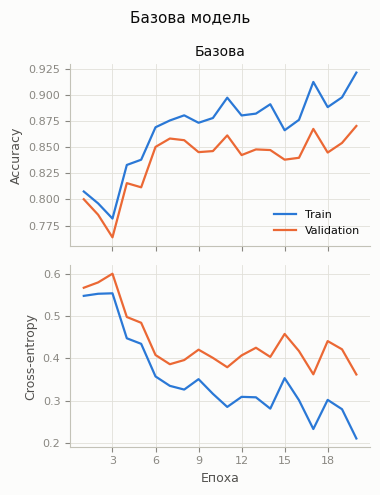

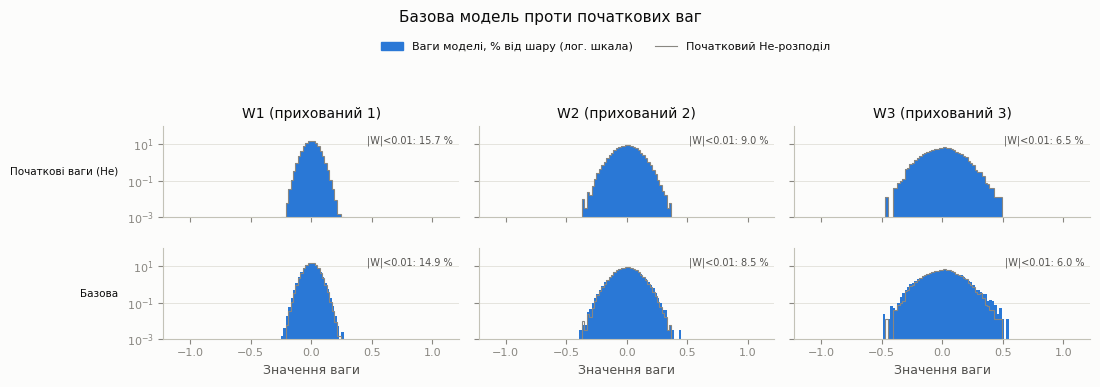

In [8]:
BASE = "Базова"
base_run = run_experiment(BASE, "Базова", "Базова")

same_history = np.allclose(base_run["history"]["val_loss"], block1_history["val_loss"])
same_init = all(np.array_equal(a, b) for a, b in zip(base_run["model"].W_init, block1_model.W_init))
print(f"\nВідтворюваність: той самий val loss, що в Блоці 1 = {same_history}, ті самі початкові ваги = {same_init}")

show_metric_tables([BASE])
plot_histories_grid([BASE], "Базова модель")
plot_weight_grid([BASE], title="Базова модель проти початкових ваг")

### 4.2. Експеримент 2. L2-регуляризація

Штраф `(λ2/2)·Σ‖W‖²`, оновлення `W ← W − η(∇W L_CE + λ2·W)`.

Доданок `λ2·W` пропорційний самій вазі, тому великі ваги стискаються сильно, а малі майже не змінюються. Розподіл стає вужчим, але точних нулів L2 майже не створює.

**На що звернути увагу:** чи зменшується розрив train−val, звужуються гістограми, чи є значення λ2, де падає вже й train accuracy, тобто починається недонавчання.

L2 λ2=0.0001         val acc=0.8758, val loss=0.3579, мертвих=0.0 %, sparsity=14.1 %, 87 с


L2 λ2=0.001          val acc=0.8632, val loss=0.3710, мертвих=0.2 %, sparsity=18.1 %, 73 с


L2 λ2=0.01           val acc=0.8288, val loss=0.4757, мертвих=2.7 %, sparsity=75.3 %, 85 с


Експеримент,Шар,Нейронів,Мертвих,% мертвих,% неактивних активацій
L2 λ2=0.0001,Прихований 1,256,0,0.0,53.8
L2 λ2=0.0001,Прихований 2,128,0,0.0,50.3
L2 λ2=0.0001,Прихований 3,64,0,0.0,48.9
L2 λ2=0.001,Прихований 1,256,0,0.0,51.5
L2 λ2=0.001,Прихований 2,128,0,0.0,45.9
L2 λ2=0.001,Прихований 3,64,1,1.6,46.1
L2 λ2=0.01,Прихований 1,256,1,0.4,37.5
L2 λ2=0.01,Прихований 2,128,5,3.9,29.0
L2 λ2=0.01,Прихований 3,64,6,9.4,40.6


Sparsity, % ваг з |W| < 0.01:


Експеримент,L2 λ2=0.0001,L2 λ2=0.001,L2 λ2=0.01
Шар,,,
W1 (Прихований 1),15.3,19.7,79.6
W2 (Прихований 2),8.7,11.2,57.7
W3 (Прихований 3),6.1,7.7,45.8
W4 (Вихідний),2.2,2.7,20.2
Усі шари,14.1,18.1,75.3


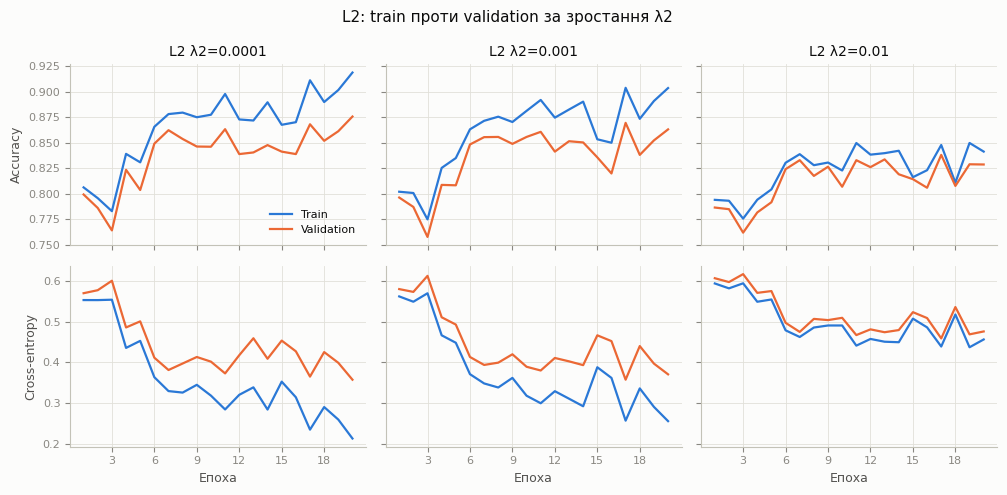

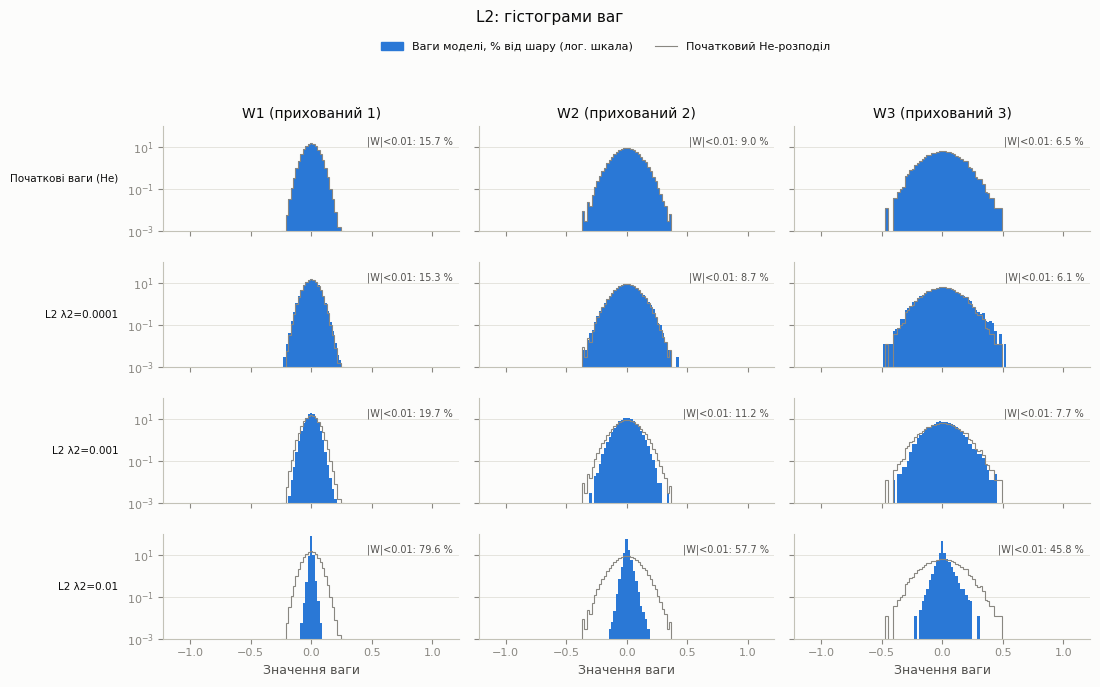

In [9]:
L2_NAMES = []
for value in L2_VALUES:
    name = f"L2 λ2={value:g}"
    L2_NAMES.append(name)
    run_experiment(name, "L2", f"L2 {value:g}", strength=value, l2=value)

show_metric_tables(L2_NAMES)
plot_histories_grid(L2_NAMES, "L2: train проти validation за зростання λ2")
plot_weight_grid(L2_NAMES, title="L2: гістограми ваг")

### 4.3. Експеримент 3. L1-регуляризація

Штраф `λ1·Σ|W|`, градієнт `λ1·sign(W)`, а `np.sign(0) = 0` дає потрібний субградієнт у нулі.

Сила L1 стала і не залежить від величини ваги, тому вона тягне малі ваги до нуля так само сильно, як і великі. Звідси й висока sparsity. Проте SGD з кроком η не робить вагу точно нульовою: вона коливається навколо нуля з амплітудою порядку η·λ1, тому sparsity логічно вимірювати порогом |W| < 0.01.

**На що звернути увагу:** пік біля нуля на гістограмах, зростання мертвих нейронів (вхідні ваги нейрона стиснулися майже до нуля, а від'ємне зміщення не дає йому активуватися) і момент, коли штраф починає шкодити точності.

L1 λ1=1e-05          val acc=0.8668, val loss=0.3674, мертвих=0.0 %, sparsity=17.3 %, 100 с


L1 λ1=0.0001         val acc=0.8472, val loss=0.3975, мертвих=0.0 %, sparsity=50.4 %, 140 с


L1 λ1=0.001          val acc=0.8112, val loss=0.5065, мертвих=23.2 %, sparsity=98.8 %, 73 с


Експеримент,Шар,Нейронів,Мертвих,% мертвих,% неактивних активацій
L1 λ1=1e-05,Прихований 1,256,0,0.0,54.5
L1 λ1=1e-05,Прихований 2,128,0,0.0,50.3
L1 λ1=1e-05,Прихований 3,64,0,0.0,48.2
L1 λ1=0.0001,Прихований 1,256,0,0.0,51.1
L1 λ1=0.0001,Прихований 2,128,0,0.0,46.8
L1 λ1=0.0001,Прихований 3,64,0,0.0,47.9
L1 λ1=0.001,Прихований 1,256,63,24.6,30.3
L1 λ1=0.001,Прихований 2,128,32,25.0,33.2
L1 λ1=0.001,Прихований 3,64,9,14.1,38.3


Sparsity, % ваг з |W| < 0.01:


Експеримент,L1 λ1=1e-05,L1 λ1=0.0001,L1 λ1=0.001
Шар,,,
W1 (Прихований 1),18.8,54.5,99.1
W2 (Прихований 2),10.8,32.9,99.0
W3 (Прихований 3),7.3,22.9,93.2
W4 (Вихідний),3.4,8.9,63.1
Усі шари,17.3,50.4,98.8


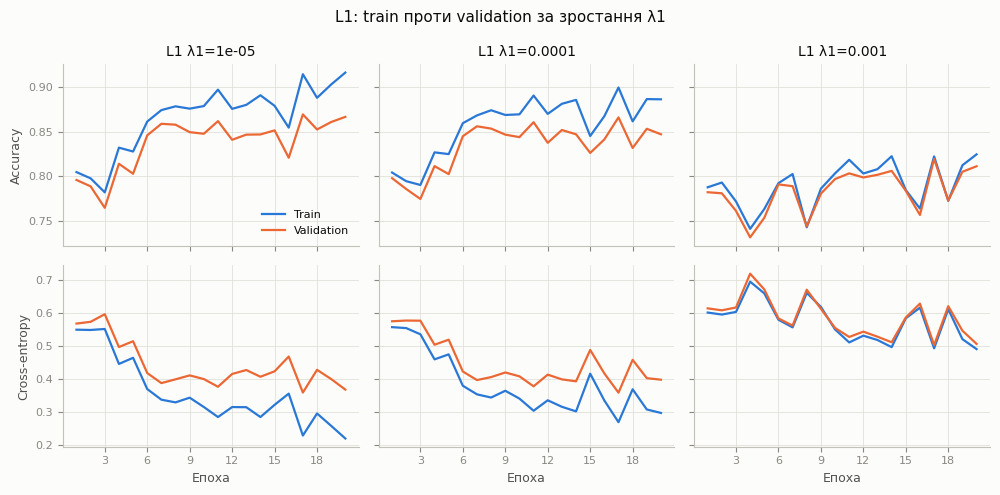

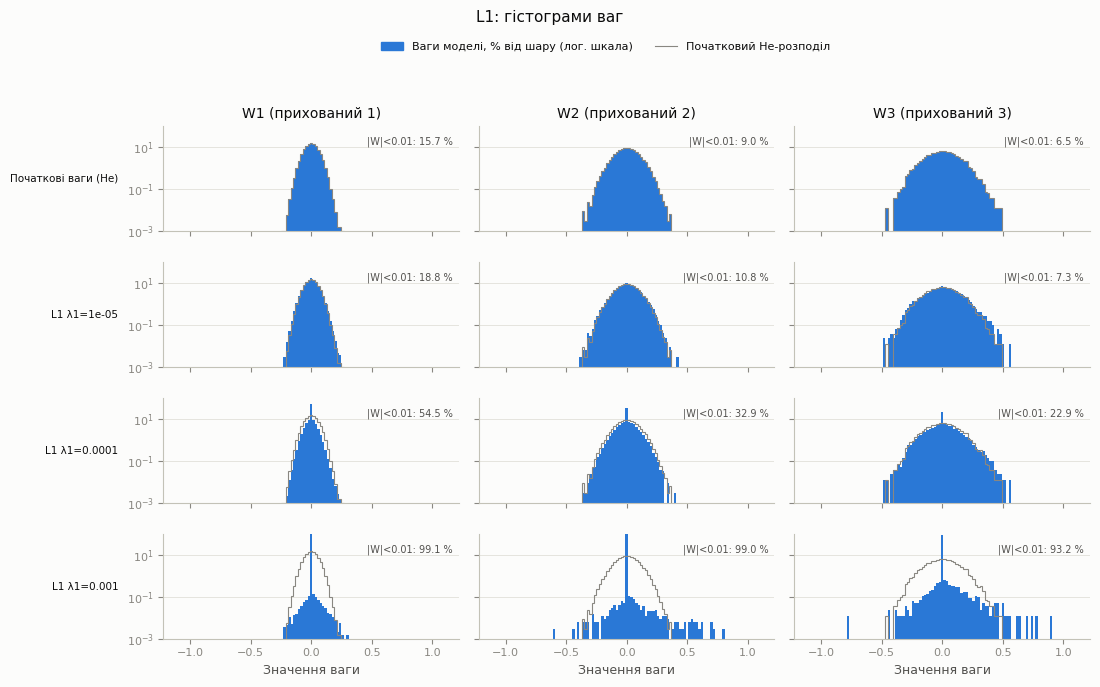

Ваг, що точно дорівнюють нулю: {'L1 λ1=1e-05': 0, 'L1 λ1=0.0001': 0, 'L1 λ1=0.001': 0}


In [10]:
L1_NAMES = []
for value in L1_VALUES:
    name = f"L1 λ1={value:g}"
    L1_NAMES.append(name)
    run_experiment(name, "L1", f"L1 {value:g}", strength=value, l1=value)

show_metric_tables(L1_NAMES)
plot_histories_grid(L1_NAMES, "L1: train проти validation за зростання λ1")
plot_weight_grid(L1_NAMES, title="L1: гістограми ваг")

exact_zero = {name: sum(int(np.sum(w == 0)) for w in RUNS[name]["model"].W) for name in L1_NAMES}
print(f"Ваг, що точно дорівнюють нулю: {exact_zero}")

### 4.4. Експеримент 4. Dropout

Inverted Dropout: маска `Bernoulli(1 − p)`, ділення на `1 − p`, лише приховані шари і лише під час навчання.

**Чому більше p не обов'язково краще.** Dropout змушує мережу не покладатися на окремі нейрони, а це зменшує коадаптацію. Проте кожен крок навчання використовує лише близько частки `1 − p` нейронів кожного шару, тож:

- за p = 0.5 ефективна ширина вужчих шарів (64 нейрони) падає приблизно до 32, і моделі може вже не вистачати ємності;
- дисперсія градієнта росте, а за малої кількості епох (тут 20) навчання просто не встигає збігтися;
- Dropout діє на всіх шарах послідовно, тому сигнал спотворюється кілька разів, і втрата інформації накопичується.

Отже, користь має оптимум: слабкий Dropout майже не впливає, а надто сильний спричиняє недонавчання. Фактичні значення наведено нижче.

**На що звернути увагу:** у цьому ноутбуці train accuracy рахується без Dropout, тому криві чесні. Якщо train і val майже збігаються, але обидві нижчі за базові, це недонавчання.

Dropout p=0.1        val acc=0.8710, val loss=0.3546, мертвих=0.0 %, sparsity=13.7 %, 59 с


Dropout p=0.3        val acc=0.8706, val loss=0.3617, мертвих=0.0 %, sparsity=13.8 %, 55 с


Dropout p=0.5        val acc=0.8486, val loss=0.4136, мертвих=0.0 %, sparsity=13.9 %, 34 с


Експеримент,Шар,Нейронів,Мертвих,% мертвих,% неактивних активацій
Dropout p=0.1,Прихований 1,256,0,0.0,66.2
Dropout p=0.1,Прихований 2,128,0,0.0,56.7
Dropout p=0.1,Прихований 3,64,0,0.0,51.5
Dropout p=0.3,Прихований 1,256,0,0.0,79.0
Dropout p=0.3,Прихований 2,128,0,0.0,62.7
Dropout p=0.3,Прихований 3,64,0,0.0,55.1
Dropout p=0.5,Прихований 1,256,0,0.0,86.2
Dropout p=0.5,Прихований 2,128,0,0.0,70.8
Dropout p=0.5,Прихований 3,64,0,0.0,55.8


Sparsity, % ваг з |W| < 0.01:


Експеримент,Dropout p=0.1,Dropout p=0.3,Dropout p=0.5
Шар,,,
W1 (Прихований 1),14.9,14.9,15.1
W2 (Прихований 2),8.9,9.0,9.0
W3 (Прихований 3),6.0,6.3,6.1
W4 (Вихідний),2.3,1.7,2.3
Усі шари,13.7,13.8,13.9


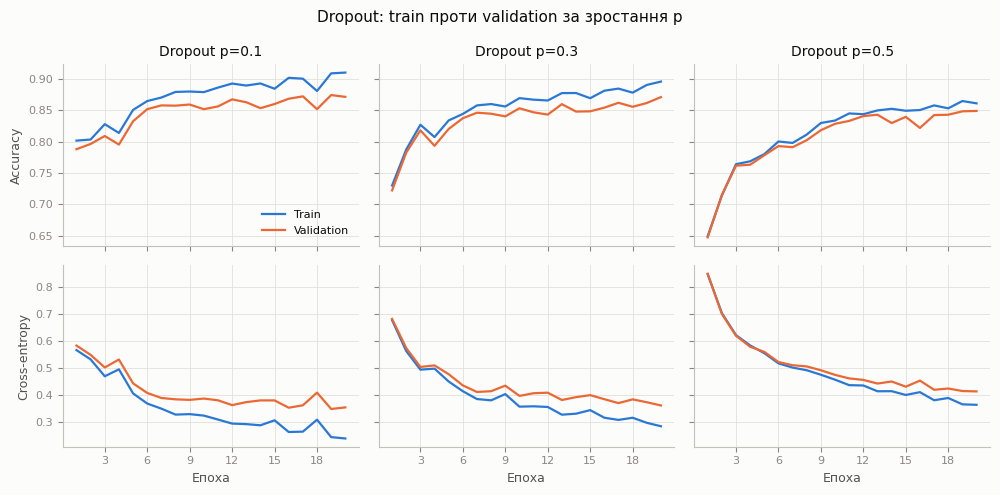

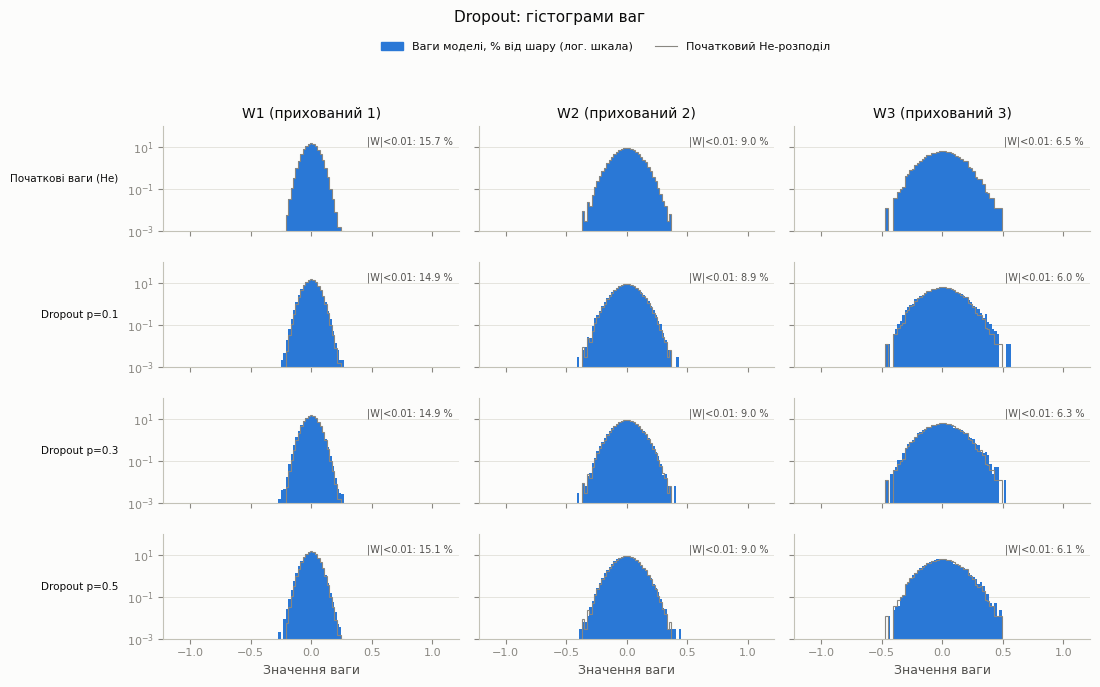

In [11]:
DROPOUT_NAMES = []
for value in DROPOUT_VALUES:
    name = f"Dropout p={value:g}"
    DROPOUT_NAMES.append(name)
    run_experiment(name, "Dropout", f"Dropout {value:g}", strength=value, dropout_p=value)

show_metric_tables(DROPOUT_NAMES)
plot_histories_grid(DROPOUT_NAMES, "Dropout: train проти validation за зростання p")
plot_weight_grid(DROPOUT_NAMES, title="Dropout: гістограми ваг")

In [12]:
base_val = RUNS[BASE]["val_acc"]
lines = [f"**Фактичні результати Dropout** (базова модель: val accuracy {pct(base_val)}, розрив train−val {100 * (RUNS[BASE]['train_acc'] - base_val):.2f} в.п.):", ""]
for name in DROPOUT_NAMES:
    run = RUNS[name]
    lines.append(f"- {name}: val accuracy {pct(run['val_acc'])} (середнє за 5 епох {pct(run['val_acc5'])}), train accuracy {pct(run['train_acc'])}, розрив {100 * (run['train_acc'] - run['val_acc']):.2f} в.п.")
lines.append(f"\nСередня val accuracy базової моделі за 5 епох: {pct(RUNS[BASE]['val_acc5'])}.")
best_dropout = max(DROPOUT_NAMES, key=lambda n: RUNS[n]["val_acc5"])
if best_dropout == DROPOUT_NAMES[-1]:
    lines.append(f"\nУ цьому запуску найбільше значення p дало найкращу середню val accuracy. Це не спростовує теорію: за інших умов (менша мережа, менше епох) перевага може зникнути.")
else:
    lines.append(f"\nНайкраща середня val accuracy у {best_dropout}, а не за найбільшого p. Отже, тут більше p не означає кращу точність.")
md("\n".join(lines))

**Фактичні результати Dropout** (базова модель: val accuracy 87.02 %, розрив train−val 5.10 в.п.):

- Dropout p=0.1: val accuracy 87.10 % (середнє за 5 епох 86.72 %), train accuracy 90.95 %, розрив 3.85 в.п.
- Dropout p=0.3: val accuracy 87.06 % (середнє за 5 епох 86.05 %), train accuracy 89.53 %, розрив 2.46 в.п.
- Dropout p=0.5: val accuracy 84.86 % (середнє за 5 епох 84.06 %), train accuracy 86.06 %, розрив 1.21 в.п.

Середня val accuracy базової моделі за 5 епох: 85.52 %.

Найкраща середня val accuracy у Dropout p=0.1, а не за найбільшого p. Отже, тут більше p не означає кращу точність.

### 4.5. Експеримент 5. Weight clipping

Після кожного оновлення `W ← clip(W, −1, 1)`. Це жорстке обмеження: допустима область для кожної ваги є гіперкубом.

**Вплив на пошук оптимальних ваг.** Якщо оптимум лежить поза межами, вага впирається в межу й там лишається, поки градієнт не поміняє знак. Обмеження не залежить від корисності ваги і не має «м'якого» тяжіння, як L2, тому біля межі виникає пік на гістограмі, а оптимізатор фактично втрачає цей ступінь свободи. Це спотворює напрям кроку: частина компонентів не оновлюється, а інші оновлюються, ніби нічого не сталося.

**Чесне зауваження про He-ініціалізацію.** За He-ініціалізації стандартне відхилення становить √(2/n_in): приблизно 0.05 для W1 і 0.18 для W4. Отже, межа ±1 лежить дуже далеко від старту, у W1 це близько 20σ. Існує реальна ймовірність, що ±1 майже не спрацює. Тому, крім обов'язкового варіанта, є додатковий контрольний запуск з межею ±0.1, яка гарантовано активна, щоб показати, як виглядає справді жорстке обмеження. Перевірка нижче показує, чи спрацювала межа ±1.

WClip ±1             val acc=0.8702, val loss=0.3621, мертвих=0.0 %, sparsity=13.7 %, 39 с


WClip ±0.1 (дод.)    val acc=0.8578, val loss=0.4019, мертвих=0.2 %, sparsity=13.6 %, 33 с

WClip ±1: ваги на межах ±1


Шар,Ваг,На межі −,На межі +,% на межах,Спрацювань за навчання,max|W|
W1,200704,0,0,0.00,0,0.255
W2,32768,0,0,0.00,0,0.436
W3,8192,0,0,0.00,0,0.533
W4,640,0,0,0.00,0,0.831



WClip ±0.1 (дод.): ваги на межах ±0.1


Шар,Ваг,На межі −,На межі +,% на межах,Спрацювань за навчання,max|W|
W1,200704,280,276,0.28,3175038,0.100
W2,32768,315,437,2.29,3369775,0.100
W3,8192,283,285,6.93,1942318,0.100
W4,640,105,30,21.09,668915,0.100


Експеримент,Шар,Нейронів,Мертвих,% мертвих,% неактивних активацій
WClip ±1,Прихований 1,256,0,0.0,54.7
WClip ±1,Прихований 2,128,0,0.0,49.6
WClip ±1,Прихований 3,64,0,0.0,49.4
WClip ±0.1 (дод.),Прихований 1,256,0,0.0,37.9
WClip ±0.1 (дод.),Прихований 2,128,0,0.0,41.0
WClip ±0.1 (дод.),Прихований 3,64,1,1.6,46.2


Sparsity, % ваг з |W| < 0.01:


Експеримент,WClip ±1,WClip ±0.1 (дод.)
Шар,,
W1 (Прихований 1),14.9,14.8
W2 (Прихований 2),8.5,8.1
W3 (Прихований 3),6.0,5.5
W4 (Вихідний),3.3,1.7
Усі шари,13.7,13.6


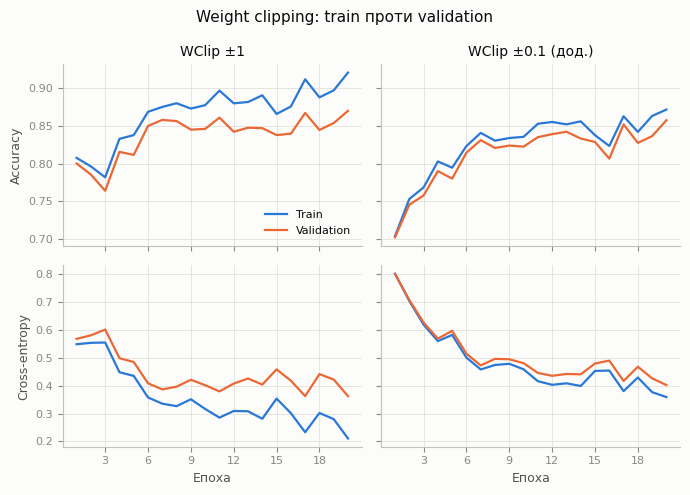

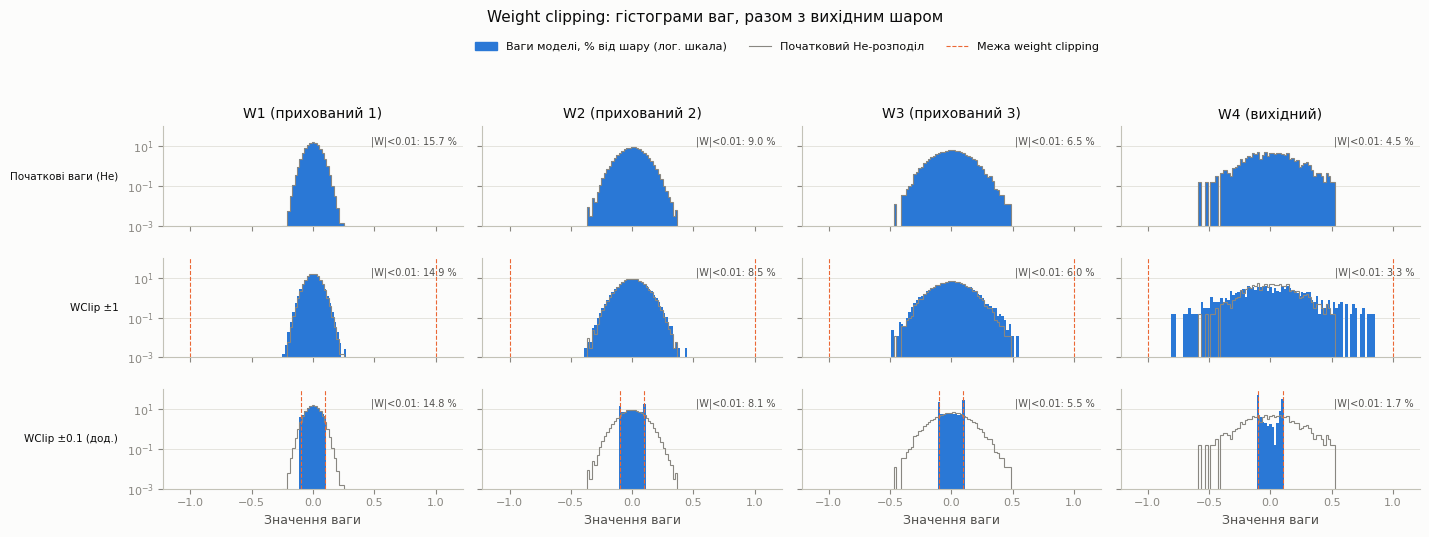

In [13]:
WCLIP_NAME = f"WClip ±{WEIGHT_CLIP_VALUE:g}"
WCLIP_TIGHT_NAME = f"WClip ±{WEIGHT_CLIP_TIGHT:g} (дод.)"
WCLIP_NAMES = [WCLIP_NAME, WCLIP_TIGHT_NAME]
run_experiment(WCLIP_NAME, "Weight clipping", WCLIP_NAME, strength=WEIGHT_CLIP_VALUE, weight_clip=WEIGHT_CLIP_VALUE)
run_experiment(WCLIP_TIGHT_NAME, "Weight clipping", f"WClip ±{WEIGHT_CLIP_TIGHT:g}", strength=WEIGHT_CLIP_TIGHT, weight_clip=WEIGHT_CLIP_TIGHT)

for name, bound in ((WCLIP_NAME, WEIGHT_CLIP_VALUE), (WCLIP_TIGHT_NAME, WEIGHT_CLIP_TIGHT)):
    print(f"\n{name}: ваги на межах ±{bound:g}")
    display(bound_table(RUNS[name]["model"], bound).style.hide(axis="index").format({"% на межах": "{:.2f}", "max|W|": "{:.3f}"}))

show_metric_tables(WCLIP_NAMES)
plot_histories_grid(WCLIP_NAMES, "Weight clipping: train проти validation")
plot_weight_grid(WCLIP_NAMES, layers=(0, 1, 2, 3), title="Weight clipping: гістограми ваг, разом з вихідним шаром")

In [14]:
clip_model = RUNS[WCLIP_NAME]["model"]
clip_events = int(clip_model.clip_events.sum())
at_bound = sum(int(np.sum(np.abs(w) >= WEIGHT_CLIP_VALUE)) for w in clip_model.W)
n_weights = sum(w.size for w in clip_model.W)
base_max_hidden = max(float(np.abs(w).max()) for w in RUNS[BASE]["model"].W[:-1])
base_max_all = max(float(np.abs(w).max()) for w in RUNS[BASE]["model"].W)
identical = all(np.array_equal(a, b) for a, b in zip(clip_model.W, RUNS[BASE]["model"].W))
tight_model = RUNS[WCLIP_TIGHT_NAME]["model"]
tight_at_bound = sum(int(np.sum(np.abs(w) >= WEIGHT_CLIP_TIGHT)) for w in tight_model.W)

events_by_layer = ", ".join(f"W{i + 1}: {int(count)}" for i, count in enumerate(clip_model.clip_events))
if identical:
    honest = f"Межа ±{WEIGHT_CLIP_VALUE:g} **жодного разу не спрацювала**, а отримана модель побітово збігається з базовою."
elif at_bound / n_weights < 0.001:
    honest = (
        f"Межа ±{WEIGHT_CLIP_VALUE:g} **майже не спрацьовує**. Ваг на межі наприкінці навчання: {at_bound} із {n_weights}. "
        f"Кількість спрацювань за все навчання: {clip_events} ({events_by_layer}). "
        "Такі поодинокі обрізання не можуть діяти як регуляризація, тому різницю в точності порівняно з базовою моделлю тут не слід приписувати методу: "
        "навіть мала зміна ваг зсуває подальшу траєкторію SGD."
    )
else:
    honest = (
        f"Межа ±{WEIGHT_CLIP_VALUE:g} спрацьовує помітно. Ваг на межі наприкінці навчання: {at_bound} із {n_weights} ({100 * at_bound / n_weights:.2f} %). "
        f"Кількість спрацювань за все навчання: {clip_events} ({events_by_layer})."
    )

md(
    f"""**Фактичні результати weight clipping.** {honest}

Для порівняння: у базовій моделі без обмеження max|W| у прихованих шарах (W1–W3) становить {base_max_hidden:.3f}, а з вихідним шаром {base_max_all:.3f}.

Val accuracy: базова {pct(RUNS[BASE]['val_acc'])}, ±{WEIGHT_CLIP_VALUE:g} {pct(RUNS[WCLIP_NAME]['val_acc'])}, ±{WEIGHT_CLIP_TIGHT:g} {pct(RUNS[WCLIP_TIGHT_NAME]['val_acc'])}.

Додаткова межа ±{WEIGHT_CLIP_TIGHT:g} утримує на межах {tight_at_bound} ваг із {n_weights} ({100 * tight_at_bound / n_weights:.1f} %), і саме на ній видно піки на гістограмах. Тому варіант ±{WEIGHT_CLIP_TIGHT:g} показує, як працює активна жорстка межа, а ±{WEIGHT_CLIP_VALUE:g} показує, що ефект методу цілком залежить від відношення межі до реального масштабу ваг."""
)

**Фактичні результати weight clipping.** Межа ±1 **жодного разу не спрацювала**, а отримана модель побітово збігається з базовою.

Для порівняння: у базовій моделі без обмеження max|W| у прихованих шарах (W1–W3) становить 0.533, а з вихідним шаром 0.831.

Val accuracy: базова 87.02 %, ±1 87.02 %, ±0.1 85.78 %.

Додаткова межа ±0.1 утримує на межах 2011 ваг із 242304 (0.8 %), і саме на ній видно піки на гістограмах. Тому варіант ±0.1 показує, як працює активна жорстка межа, а ±1 показує, що ефект методу цілком залежить від відношення межі до реального масштабу ваг.

### 4.6. Експеримент 6. Gradient clipping

Обрізання за глобальною L2-нормою всіх градієнтів (W і b разом): `g ← g·min(1, c/‖g‖)`. Напрям кроку зберігається, змінюється лише довжина.

**Відмінність від weight clipping:**

| | Gradient clipping | Weight clipping |
|---|---|---|
| Що обмежує | довжину кроку | значення самих ваг |
| Коли діє | лише коли ‖g‖ > c | щоразу, коли вага виходить за межу |
| Ваги можуть рости? | так, але повільніше | ні, вони лишаються в гіперкубі |
| Напрям кроку | зберігається | спотворюється покомпонентно |
| Мета | стабільність навчання | пряме обмеження масштабу ваг |

Gradient clipping не є регуляризатором у класичному сенсі: він не змінює функцію втрат, а змінює траєкторію оптимізації. Мале c фактично зменшує learning rate.

**На що звернути увагу:** наскільки loss на мінібатчах стає рівнішим, як часто спрацьовує обрізання (норму видно на нижньому ряду графіків) і чи не сповільнилося навчання за малого c.

GClip c=0.5          val acc=0.8568, val loss=0.4105, мертвих=0.9 %, sparsity=14.3 %, 25 с


GClip c=1            val acc=0.8654, val loss=0.3763, мертвих=0.4 %, sparsity=14.1 %, 26 с


GClip c=5            val acc=0.8712, val loss=0.3644, мертвих=0.0 %, sparsity=13.6 %, 29 с


Експеримент,Шар,Нейронів,Мертвих,% мертвих,% неактивних активацій
GClip c=0.5,Прихований 1,256,0,0.0,41.2
GClip c=0.5,Прихований 2,128,0,0.0,42.7
GClip c=0.5,Прихований 3,64,4,6.2,41.4
GClip c=1,Прихований 1,256,0,0.0,45.2
GClip c=1,Прихований 2,128,0,0.0,45.0
GClip c=1,Прихований 3,64,2,3.1,45.4
GClip c=5,Прихований 1,256,0,0.0,54.7
GClip c=5,Прихований 2,128,0,0.0,49.5
GClip c=5,Прихований 3,64,0,0.0,50.8


Sparsity, % ваг з |W| < 0.01:


Експеримент,GClip c=0.5,GClip c=1,GClip c=5
Шар,,,
W1 (Прихований 1),15.5,15.4,14.8
W2 (Прихований 2),8.8,8.7,8.4
W3 (Прихований 3),6.1,6.1,5.8
W4 (Вихідний),3.6,3.3,2.8
Усі шари,14.3,14.1,13.6


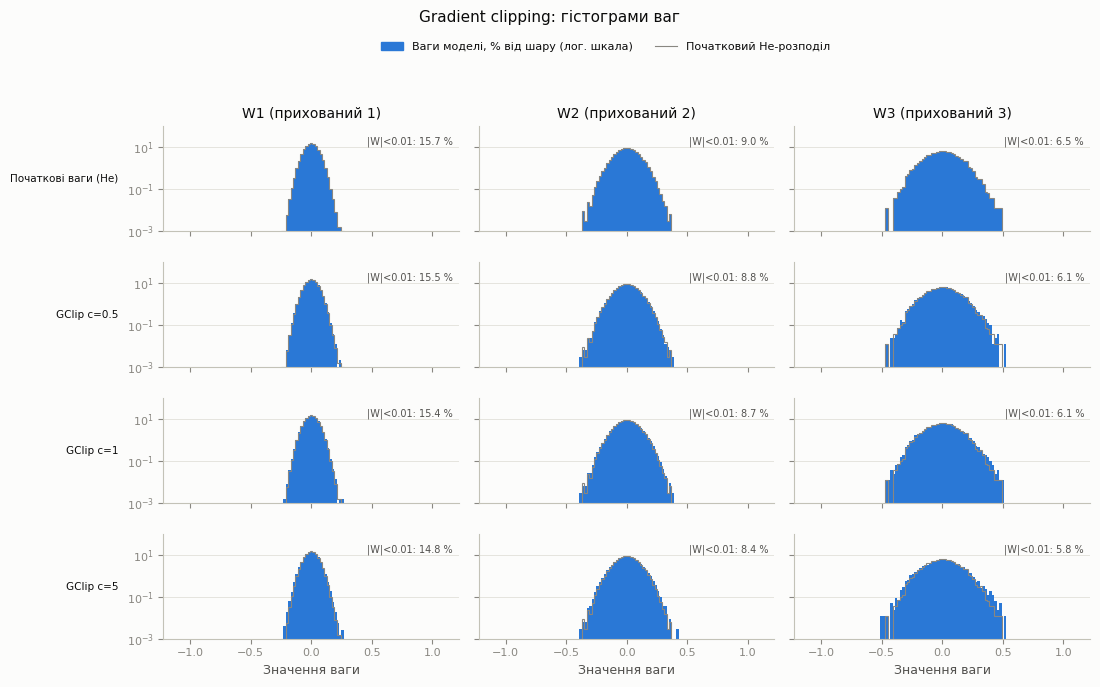

Експеримент,Std batch loss (2-га половина),Max batch loss (2-га половина),Max зростання val loss за епоху,Медіана ‖g‖,Max ‖g‖,% кроків з обрізанням,Val accuracy
Базова,0.083,0.753,0.079,1.864,6.504,0.000,0.870
GClip c=0.5,0.098,0.812,0.015,2.870,9.884,100.000,0.857
GClip c=1,0.093,0.729,0.029,2.605,8.054,99.920,0.865
GClip c=5,0.083,0.734,0.072,1.865,6.890,0.080,0.871


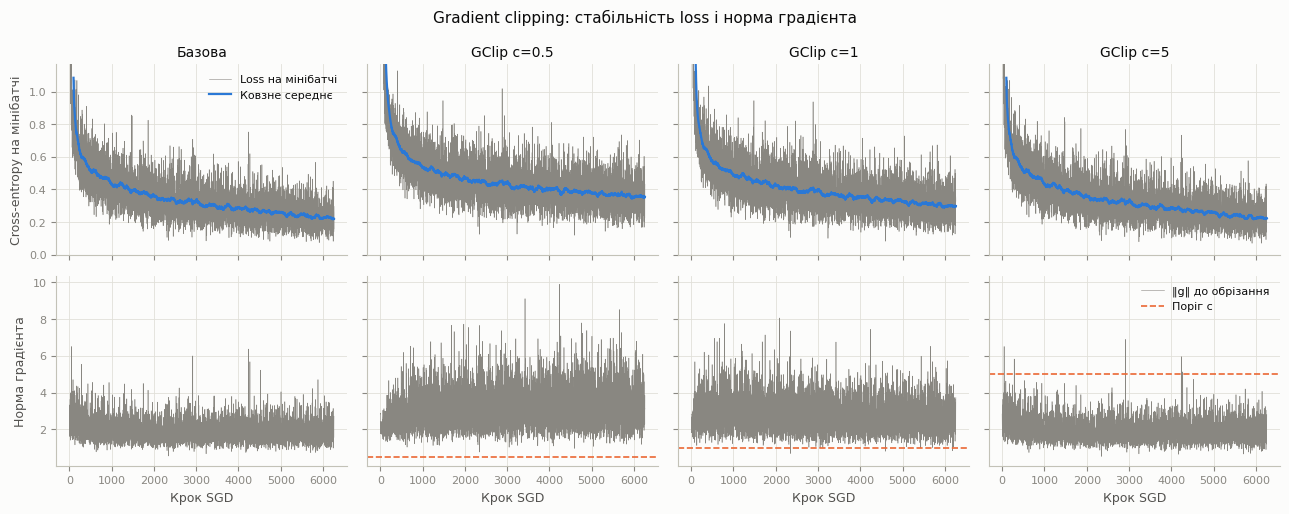

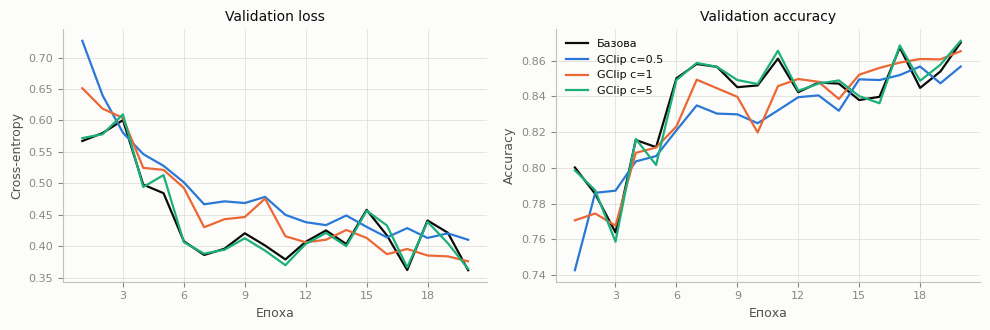

In [15]:
GCLIP_NAMES = []
for value in GRAD_CLIP_VALUES:
    name = f"GClip c={value:g}"
    GCLIP_NAMES.append(name)
    run_experiment(name, "Gradient clipping", f"GClip {value:g}", strength=value, grad_clip=value)

show_metric_tables(GCLIP_NAMES)
plot_weight_grid(GCLIP_NAMES, title="Gradient clipping: гістограми ваг")


def moving_average(values, window=100):
    values = np.asarray(values)
    window = min(window, max(1, values.size // 2))
    return np.convolve(values, np.ones(window) / window, mode="valid")


def gclip_stability_row(name):
    """Показники стабільності: шум loss за мінібатчами, сплески та частота обрізання."""
    run = RUNS[name]
    batch_loss = np.asarray(run["history"]["batch_loss"])
    norm = np.asarray(run["history"]["grad_norm"])
    second_half = batch_loss[batch_loss.size // 2 :]
    c = run["params"].get("grad_clip")
    return {
        "Експеримент": name,
        "Std batch loss (2-га половина)": second_half.std(),
        "Max batch loss (2-га половина)": second_half.max(),
        "Max зростання val loss за епоху": float(np.max(np.diff(run["history"]["val_loss"]))),
        "Медіана ‖g‖": float(np.median(norm)),
        "Max ‖g‖": float(norm.max()),
        "% кроків з обрізанням": 100 * float(np.mean(norm > c)) if c is not None else 0.0,
        "Val accuracy": run["val_acc"],
    }


GCLIP_COMPARE = [BASE] + GCLIP_NAMES
gclip_table = pd.DataFrame([gclip_stability_row(name) for name in GCLIP_COMPARE])
display(gclip_table.style.hide(axis="index").format(precision=3))

fig, axes = plt.subplots(2, len(GCLIP_COMPARE), figsize=(13, 5.2), sharex=True, sharey="row")
top_loss = np.percentile(RUNS[BASE]["history"]["batch_loss"], 99.5)
for column, name in enumerate(GCLIP_COMPARE):
    history = RUNS[name]["history"]
    steps = np.arange(len(history["batch_loss"]))
    smooth = moving_average(history["batch_loss"])
    axes[0, column].plot(steps, history["batch_loss"], color=COLORS["muted"], linewidth=0.4, label="Loss на мінібатчі")
    axes[0, column].plot(steps[-smooth.size :], smooth, color=COLORS["train"], label="Ковзне середнє")
    axes[0, column].set_title(name)
    axes[0, column].set_ylim(0, top_loss * 1.05)
    axes[1, column].plot(steps, history["grad_norm"], color=COLORS["muted"], linewidth=0.4, label="‖g‖ до обрізання")
    c = RUNS[name]["params"].get("grad_clip")
    if c is not None:
        axes[1, column].axhline(c, color=COLORS["val"], linewidth=1.2, linestyle="--", label="Поріг c")
    axes[1, column].set_xlabel("Крок SGD")
axes[0, 0].set_ylabel("Cross-entropy на мінібатчі")
axes[1, 0].set_ylabel("Норма градієнта")
axes[0, 0].legend(loc="upper right")
axes[1, -1].legend(loc="upper right")
fig.suptitle("Gradient clipping: стабільність loss і норма градієнта", fontsize=11)
fig.tight_layout()
plt.show()

gclip_colors = [COLORS["ink"], COLORS["train"], COLORS["val"], COLORS["third"]]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharex=True)
for name, color in zip(GCLIP_COMPARE, gclip_colors):
    history = RUNS[name]["history"]
    epochs_axis = np.arange(1, len(history["val_loss"]) + 1)
    axes[0].plot(epochs_axis, history["val_loss"], color=color, label=name)
    axes[1].plot(epochs_axis, history["val_acc"], color=color, label=name)
axes[0].set(title="Validation loss", xlabel="Епоха", ylabel="Cross-entropy")
axes[1].set(title="Validation accuracy", xlabel="Епоха", ylabel="Accuracy")
axes[1].xaxis.set_major_locator(MaxNLocator(integer=True))
axes[1].legend()
fig.tight_layout()
plt.show()

In [16]:
base_row = gclip_table.iloc[0]
lines = [f"**Фактичні результати gradient clipping.** Медіанна норма градієнта в базовій моделі: {base_row['Медіана ‖g‖']:.3f}, максимальна: {base_row['Max ‖g‖']:.3f}.", ""]
for _, row in gclip_table.iloc[1:].iterrows():
    change = row["Std batch loss (2-га половина)"] - base_row["Std batch loss (2-га половина)"]
    if abs(change) < 0.001:
        comparison = "майже як у базової"
    else:
        comparison = f"{'менше' if change < 0 else 'більше'}, ніж у базової, на {abs(change):.3f}"
    lines.append(
        f"- {row['Експеримент']}: обрізання спрацювало на {row['% кроків з обрізанням']:.1f} % кроків, "
        f"std batch loss {row['Std batch loss (2-га половина)']:.3f} ({comparison}), "
        f"max batch loss {row['Max batch loss (2-га половина)']:.3f}, "
        f"max зростання val loss за епоху {row['Max зростання val loss за епоху']:.3f} "
        f"(у базової {base_row['Max зростання val loss за епоху']:.3f}), val accuracy {pct(row['Val accuracy'])}."
    )
lines.append("\nStd batch loss слід читати разом з accuracy і графіками: він залежить не лише від стабільності навчання, а й від рівня самого loss та складу мінібатчів.")
md("\n".join(lines))

**Фактичні результати gradient clipping.** Медіанна норма градієнта в базовій моделі: 1.864, максимальна: 6.504.

- GClip c=0.5: обрізання спрацювало на 100.0 % кроків, std batch loss 0.098 (більше, ніж у базової, на 0.015), max batch loss 0.812, max зростання val loss за епоху 0.015 (у базової 0.079), val accuracy 85.68 %.
- GClip c=1: обрізання спрацювало на 99.9 % кроків, std batch loss 0.093 (більше, ніж у базової, на 0.010), max batch loss 0.729, max зростання val loss за епоху 0.029 (у базової 0.079), val accuracy 86.54 %.
- GClip c=5: обрізання спрацювало на 0.1 % кроків, std batch loss 0.083 (майже як у базової), max batch loss 0.734, max зростання val loss за епоху 0.072 (у базової 0.079), val accuracy 87.12 %.

Std batch loss слід читати разом з accuracy і графіками: він залежить не лише від стабільності навчання, а й від рівня самого loss та складу мінібатчів.

### 4.7. Експеримент 7. Комбінація L2 + Dropout

λ2 вибирається автоматично за найкращою val accuracy з експерименту 2 (середнє за останні 5 епох, бо фінальна епоха залежить від випадкового стрибка), Dropout p = 0.2.

Значення p = 0.2 не входить до експерименту 4, тому для чесного порівняння додано ще контрольний запуск «Dropout p=0.2» окремо. Інакше різницю між комбінацією й Dropout не можна було б відокремити від різниці в p.

**Синергія** — комбінація краща за кожен метод окремо, причому більше, ніж на рівень шуму. **Надмірне обмеження** — комбінація гірша за обидва методи, а train accuracy теж падає.

Оскільки λ2 вибирається за тією ж валідаційною вибіркою, на якій порівнюються моделі, оцінка для цього варіанта трохи оптимістична.

Найкраще L2 з експерименту 2: L2 λ2=0.0001


Dropout p=0.2 (контроль) val acc=0.8632, val loss=0.3676, мертвих=0.0 %, sparsity=13.7 %, 29 с


L2+Dropout (λ2=0.0001, p=0.2) val acc=0.8666, val loss=0.3590, мертвих=0.0 %, sparsity=14.1 %, 43 с


Експеримент,Шар,Нейронів,Мертвих,% мертвих,% неактивних активацій
Базова,Прихований 1,256,0,0.0,54.7
Базова,Прихований 2,128,0,0.0,49.6
Базова,Прихований 3,64,0,0.0,49.4
L2 λ2=0.0001,Прихований 1,256,0,0.0,53.8
L2 λ2=0.0001,Прихований 2,128,0,0.0,50.3
L2 λ2=0.0001,Прихований 3,64,0,0.0,48.9
Dropout p=0.2 (контроль),Прихований 1,256,0,0.0,72.9
Dropout p=0.2 (контроль),Прихований 2,128,0,0.0,60.8
Dropout p=0.2 (контроль),Прихований 3,64,0,0.0,52.8
"L2+Dropout (λ2=0.0001, p=0.2)",Прихований 1,256,0,0.0,72.5


Sparsity, % ваг з |W| < 0.01:


Експеримент,Базова,L2 λ2=0.0001,Dropout p=0.2 (контроль),"L2+Dropout (λ2=0.0001, p=0.2)"
Шар,,,,
W1 (Прихований 1),14.9,15.3,14.9,15.3
W2 (Прихований 2),8.5,8.7,8.7,9.1
W3 (Прихований 3),6.0,6.1,5.9,6.1
W4 (Вихідний),3.3,2.2,2.7,3.1
Усі шари,13.7,14.1,13.7,14.1


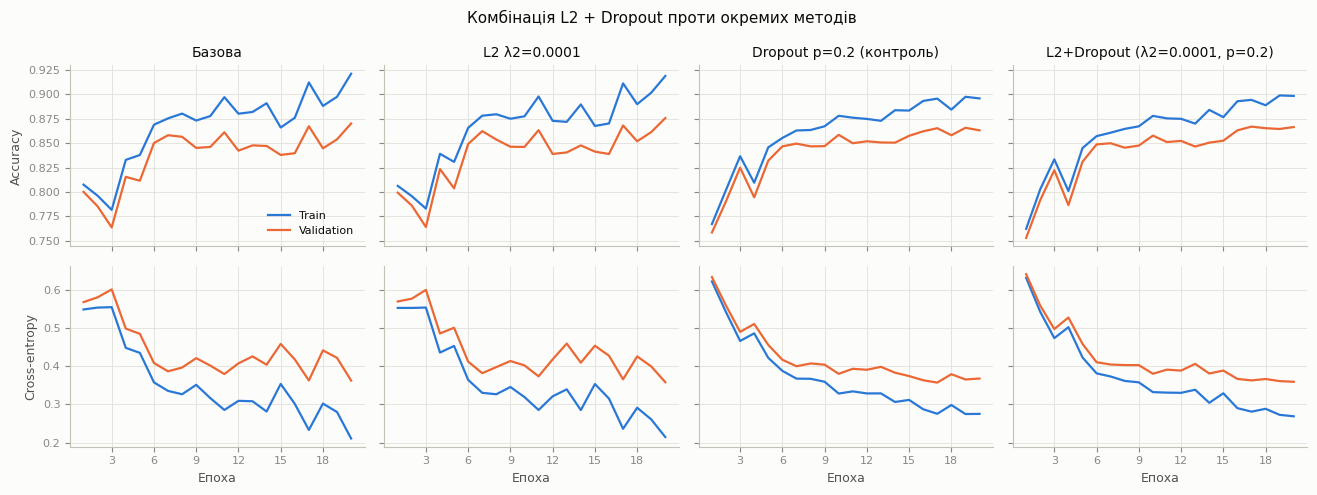

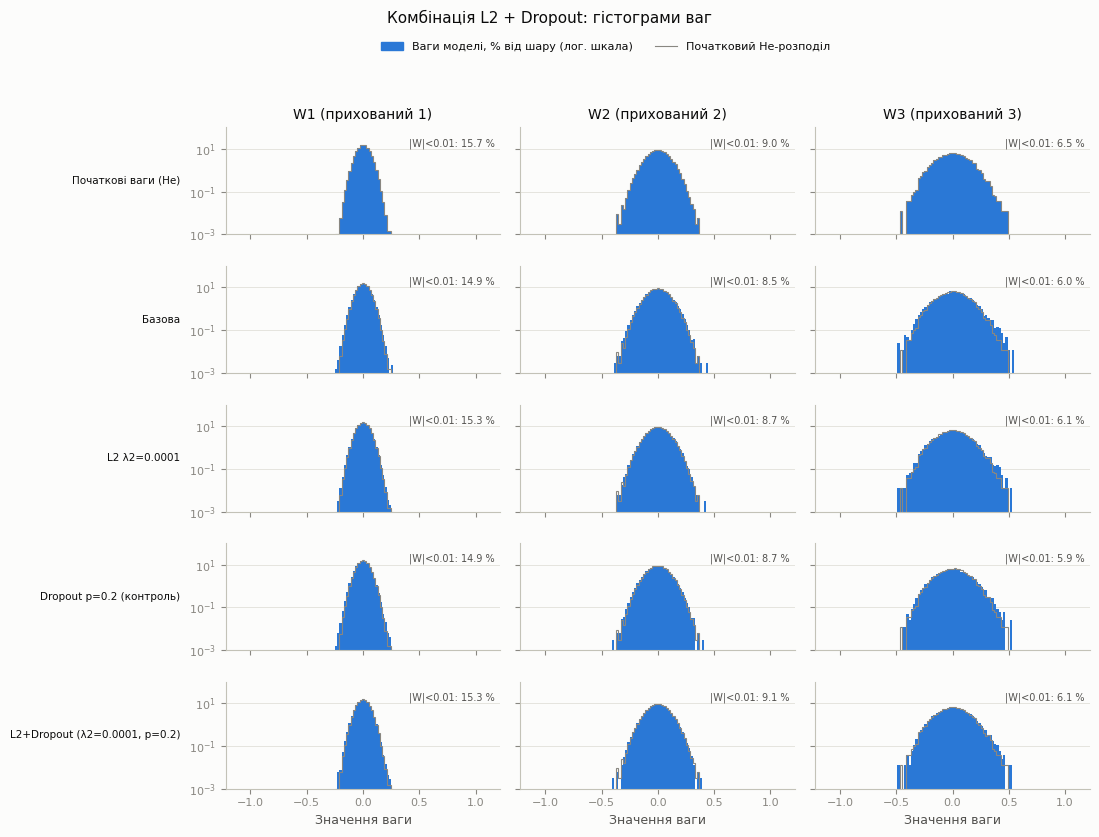

**Фактичний результат комбінації.** Рівень шуму val accuracy: статистична похибка на 5000 прикладах ±0.48 в.п., коливання базової моделі за останні 5 епох ±1.20 в.п. Поріг для фінальної епохи ±1.20 в.п., поріг для середнього за 5 епох ±0.54 в.п. Висновок нижче спирається на середнє за 5 епох.

| Модель | Train acc | Val acc | Train, сер. 5 епох | Val, сер. 5 епох | Розрив за середнім | Val loss |
|---|---|---|---|---|---|---|
| Базова | 92.12 % | 87.02 % | 89.90 % | 85.52 % | 4.38 в.п. | 0.3621 |
| L2 λ2=0.0001 | 91.89 % | 87.58 % | 89.84 % | 85.93 % | 3.92 в.п. | 0.3579 |
| Dropout p=0.2 (контроль) | 89.59 % | 86.32 % | 89.34 % | 86.30 % | 3.04 в.п. | 0.3676 |
| L2+Dropout (λ2=0.0001, p=0.2) | 89.84 % | 86.66 % | 89.47 % | 86.54 % | 2.94 в.п. | 0.3590 |

Висновок за цими числами: **чіткої синергії за accuracy немає, як і надмірного обмеження**: різниця з кращим окремим методом порівнянна з рівнем шуму або не перевищує його.

In [17]:
BEST_L2_NAME = max(L2_NAMES, key=lambda n: RUNS[n]["val_acc5"])
BEST_L2_VALUE = RUNS[BEST_L2_NAME]["params"]["l2"]
print(f"Найкраще L2 з експерименту 2: {BEST_L2_NAME}")

DROPOUT_CONTROL_NAME = f"Dropout p={COMBO_DROPOUT:g} (контроль)"
COMBO_NAME = f"L2+Dropout (λ2={BEST_L2_VALUE:g}, p={COMBO_DROPOUT:g})"
run_experiment(DROPOUT_CONTROL_NAME, "Dropout", f"Dropout {COMBO_DROPOUT:g}", strength=COMBO_DROPOUT, dropout_p=COMBO_DROPOUT)
run_experiment(COMBO_NAME, "L2 + Dropout", f"L2+Dropout", l2=BEST_L2_VALUE, dropout_p=COMBO_DROPOUT)

COMBO_COMPARE = [BASE, BEST_L2_NAME, DROPOUT_CONTROL_NAME, COMBO_NAME]
show_metric_tables(COMBO_COMPARE)
plot_histories_grid(COMBO_COMPARE, "Комбінація L2 + Dropout проти окремих методів")
plot_weight_grid(COMBO_COMPARE, title="Комбінація L2 + Dropout: гістограми ваг")

# Шум має два джерела: скінченна вибірка і коливання моделі між епохами
NOISE_SAMPLE = float(np.sqrt(base_val * (1 - base_val) / N_VAL))
NOISE_EPOCHS = float(np.std(RUNS[BASE]["history"]["val_acc"][-5:]))
NOISE = max(NOISE_SAMPLE, NOISE_EPOCHS)
# Поріг для середнього за 5 епох: епохові коливання зменшуються в √5 разів, а похибка вибірки ні
NOISE_MEAN = max(NOISE_SAMPLE, NOISE_EPOCHS / np.sqrt(5))

l2_run, dropout_run, combo_run = RUNS[BEST_L2_NAME], RUNS[DROPOUT_CONTROL_NAME], RUNS[COMBO_NAME]
best_single = max(l2_run["val_acc5"], dropout_run["val_acc5"])
worst_single = min(l2_run["val_acc5"], dropout_run["val_acc5"])
if combo_run["val_acc5"] > best_single + NOISE_MEAN:
    combo_verdict = "**є синергія**: комбінація краща за кожен метод окремо понад рівень шуму"
elif combo_run["val_acc5"] < worst_single - NOISE_MEAN and combo_run["train_acc5"] < min(l2_run["train_acc5"], dropout_run["train_acc5"]):
    combo_verdict = "**надмірне обмеження**: і val, і train accuracy нижчі, ніж в обох методів окремо"
else:
    combo_verdict = "**чіткої синергії за accuracy немає, як і надмірного обмеження**: різниця з кращим окремим методом порівнянна з рівнем шуму або не перевищує його"

md(
    f"""**Фактичний результат комбінації.** Рівень шуму val accuracy: статистична похибка на {N_VAL} прикладах ±{100 * NOISE_SAMPLE:.2f} в.п., коливання базової моделі за останні 5 епох ±{100 * NOISE_EPOCHS:.2f} в.п. Поріг для фінальної епохи ±{100 * NOISE:.2f} в.п., поріг для середнього за 5 епох ±{100 * NOISE_MEAN:.2f} в.п. Висновок нижче спирається на середнє за 5 епох.

| Модель | Train acc | Val acc | Train, сер. 5 епох | Val, сер. 5 епох | Розрив за середнім | Val loss |
|---|---|---|---|---|---|---|
""" + "\n".join(
        f"| {n} | {pct(RUNS[n]['train_acc'])} | {pct(RUNS[n]['val_acc'])} | {pct(RUNS[n]['train_acc5'])} | {pct(RUNS[n]['val_acc5'])} | {100 * (RUNS[n]['train_acc5'] - RUNS[n]['val_acc5']):.2f} в.п. | {RUNS[n]['val_loss']:.4f} |"
        for n in COMBO_COMPARE
    ) + f"""

Висновок за цими числами: {combo_verdict}."""
)

## 5. Аналіз і порівняння

### 5.1. Зведена таблиця

Колонки Dead neurons, Sparsity, Val accuracy і Val loss стосуються фінальної моделі. Фінальна епоха може випадково виявитися вдалою чи невдалою, тому колонки «сер. 5 епох» дають середнє за останні 5 епох, і саме за ними робиться діагноз. «Рівень шуму» в правилах нижче є більшим із двох значень: статистичної похибки вибірки та стандартної похибки середнього за 5 епох для базової моделі.

Колонка «Діагноз» обчислюється кодом за такими правилами відносно базової моделі (усі accuracy тут є середніми за 5 епох):

- **колапс:** val accuracy нижча за 20 %, модель майже не відрізняється від випадкового вгадування;
- **недонавчання:** train accuracy нижча за базову більш ніж на 3 в.п., а val accuracy нижча понад рівень шуму;
- **перенавчання зменшено:** розрив train−val менший за базовий більш ніж на 1 в.п., а val accuracy не впала понад рівень шуму;
- **менший розрив ціною точності:** розрив зменшився, але й val accuracy нижча понад рівень шуму;
- **без суттєвих змін:** решта випадків.

In [18]:
base = RUNS[BASE]
base_gap = base["train_acc5"] - base["val_acc5"]


def diagnose(run):
    gap = run["train_acc5"] - run["val_acc5"]
    if run is base:
        return "еталон"
    if run["val_acc5"] < 0.2:
        return "колапс"
    if run["train_acc5"] < base["train_acc5"] - 0.03 and run["val_acc5"] < base["val_acc5"] - NOISE_MEAN:
        return "недонавчання"
    if gap < base_gap - 0.01:
        return "перенавчання зменшено" if run["val_acc5"] >= base["val_acc5"] - NOISE_MEAN else "менший розрив ціною точності"
    return "без суттєвих змін"


rows = []
for name, run in RUNS.items():
    params = run["params"]
    rows.append(
        {
            "Експеримент": name,
            "Метод": run["family"],
            "λ1": params.get("l1", np.nan),
            "λ2": params.get("l2", np.nan),
            "p": params.get("dropout_p", np.nan),
            "c (grad)": params.get("grad_clip", np.nan),
            "Межа W": params.get("weight_clip", np.nan),
            "Dead neurons %": run["dead_pct"],
            "Sparsity %": run["sparsity_pct"],
            "Train accuracy": run["train_acc"],
            "Val accuracy": run["val_acc"],
            "Train acc, сер. 5 епох": run["train_acc5"],
            "Val acc, сер. 5 епох": run["val_acc5"],
            "Розрив, сер. 5 епох": run["train_acc5"] - run["val_acc5"],
            "Val loss": run["val_loss"],
            "Діагноз": diagnose(run),
        }
    )
summary = pd.DataFrame(rows)
summary.to_csv(ARTIFACTS_DIR / "summary.csv", index=False, encoding="utf-8-sig")

display(
    summary.style.hide(axis="index").format(
        {
            "λ1": "{:g}",
            "λ2": "{:g}",
            "p": "{:g}",
            "c (grad)": "{:g}",
            "Межа W": "{:g}",
            "Dead neurons %": "{:.1f}",
            "Sparsity %": "{:.1f}",
            "Train accuracy": "{:.4f}",
            "Val accuracy": "{:.4f}",
            "Train acc, сер. 5 епох": "{:.4f}",
            "Val acc, сер. 5 епох": "{:.4f}",
            "Розрив, сер. 5 епох": "{:.4f}",
            "Val loss": "{:.4f}",
        },
        na_rep="—",
    )
)

best_row = summary.loc[summary["Val accuracy"].idxmax()]
best_mean_row = summary.loc[summary["Val acc, сер. 5 епох"].idxmax()]
print(f"Найкраща val accuracy на фінальній епосі: {best_row['Експеримент']} ({best_row['Val accuracy']:.4f})")
print(f"Найкраща val accuracy за середнім 5 епох: {best_mean_row['Експеримент']} ({best_mean_row['Val acc, сер. 5 епох']:.4f})")
print(f"Рівень шуму: фінальна епоха ±{100 * NOISE:.2f} в.п., середнє за 5 епох ±{100 * NOISE_MEAN:.2f} в.п.")

Експеримент,Метод,λ1,λ2,p,c (grad),Межа W,Dead neurons %,Sparsity %,Train accuracy,Val accuracy,"Train acc, сер. 5 епох","Val acc, сер. 5 епох","Розрив, сер. 5 епох",Val loss,Діагноз
Базова,Базова,—,—,—,—,—,0.0,13.7,0.9212,0.8702,0.8990,0.8552,0.0438,0.3621,еталон
L2 λ2=0.0001,L2,—,0.0001,—,—,—,0.0,14.1,0.9189,0.8758,0.8984,0.8593,0.0392,0.3579,без суттєвих змін
L2 λ2=0.001,L2,—,0.001,—,—,—,0.2,18.1,0.9037,0.8632,0.8845,0.8487,0.0358,0.3710,без суттєвих змін
L2 λ2=0.01,L2,—,0.01,—,—,—,2.7,75.3,0.8415,0.8288,0.8347,0.8220,0.0127,0.4757,недонавчання
L1 λ1=1e-05,L1,1e-05,—,—,—,—,0.0,17.3,0.9166,0.8668,0.8955,0.8542,0.0414,0.3674,без суттєвих змін
L1 λ1=0.0001,L1,0.0001,—,—,—,—,0.0,50.4,0.8865,0.8472,0.8805,0.8480,0.0325,0.3975,менший розрив ціною точності
L1 λ1=0.001,L1,0.001,—,—,—,—,23.2,98.8,0.8246,0.8112,0.7990,0.7929,0.0061,0.5065,недонавчання
Dropout p=0.1,Dropout,—,—,0.1,—,—,0.0,13.7,0.9095,0.8710,0.8998,0.8672,0.0326,0.3546,перенавчання зменшено
Dropout p=0.3,Dropout,—,—,0.3,—,—,0.0,13.8,0.8952,0.8706,0.8855,0.8605,0.0250,0.3617,перенавчання зменшено
Dropout p=0.5,Dropout,—,—,0.5,—,—,0.0,13.9,0.8607,0.8486,0.8570,0.8406,0.0165,0.4136,недонавчання


Найкраща val accuracy на фінальній епосі: L2 λ2=0.0001 (0.8758)
Найкраща val accuracy за середнім 5 епох: Dropout p=0.1 (0.8672)
Рівень шуму: фінальна епоха ±1.20 в.п., середнє за 5 епох ±0.54 в.п.


### 5.2. Гістограми ваг: порівняння всіх моделей

Рядки: початкові ваги, базова модель, далі всі експерименти. Осі однакові в усіх панелях. Центральний стовпчик відповідає |W| < 0.01. Вихідний шар W4 додано тому, що зазвичай саме там ваги найбільші, а це важливо для weight clipping. Нижче таблиця дає кількість ваг біля нуля і на межах.

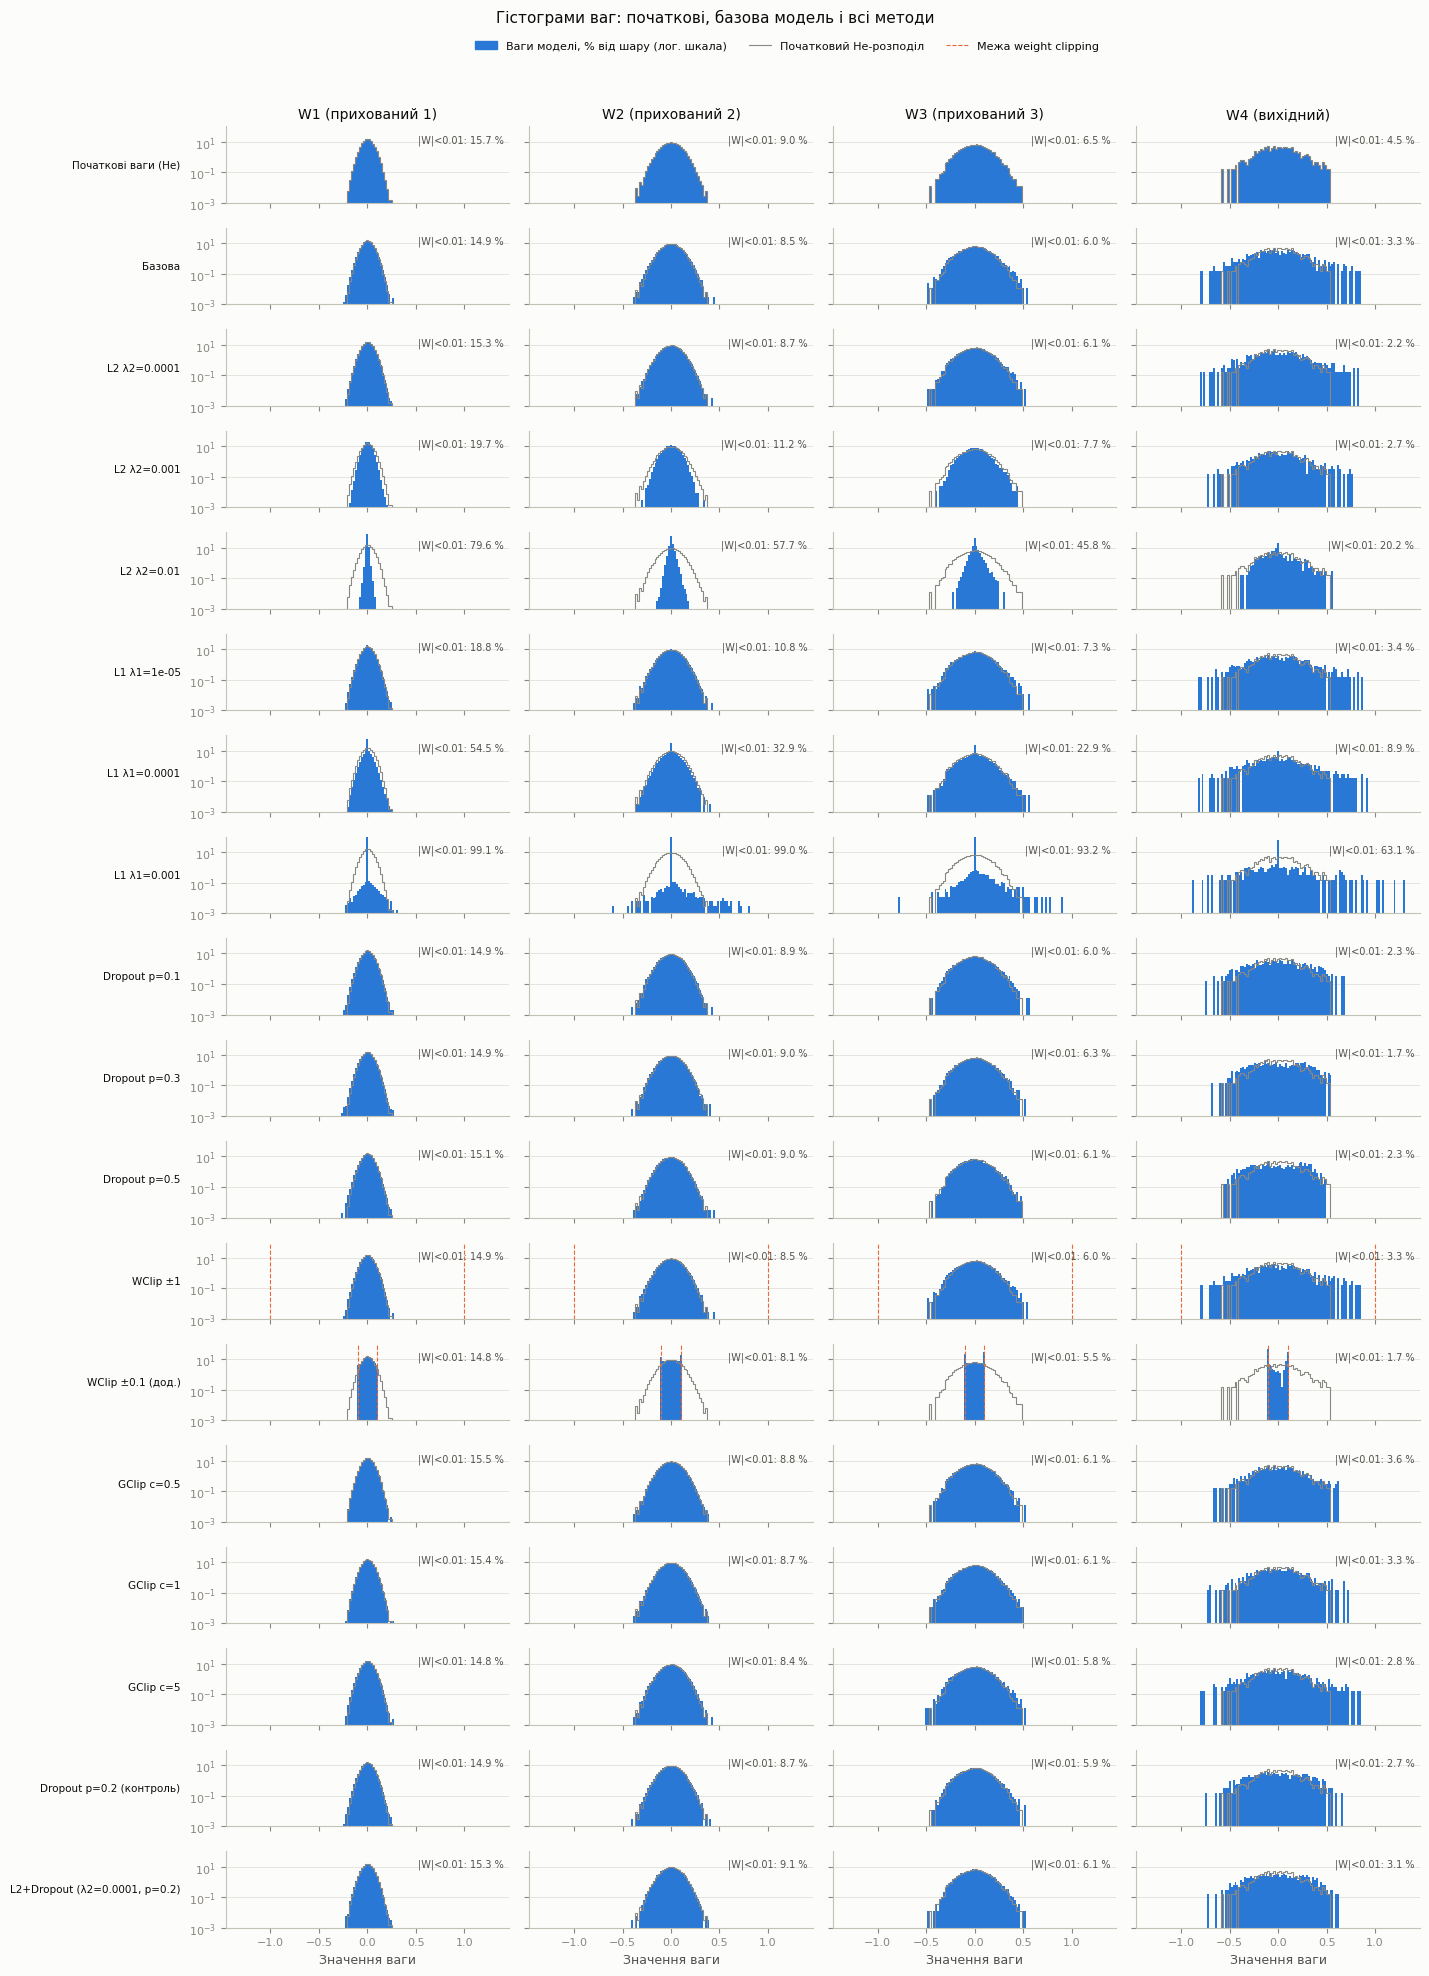

Експеримент,"|W|<0.01, усі шари",Sparsity %,Точних нулів,max|W| (W1–W3),max|W| (W4),Біля ±1 (0.99≤|W|≤1.01)
Базова,33118,13.7,0,0.533,0.831,0
L2 λ2=0.0001,34083,14.1,0,0.516,0.826,0
L2 λ2=0.001,43940,18.1,0,0.443,0.768,0
L2 λ2=0.01,182518,75.3,0,0.294,0.560,0
L1 λ1=1e-05,41864,17.3,0,0.554,0.857,0
L1 λ1=0.0001,122010,50.4,0,0.557,0.928,0
L1 λ1=0.001,239457,98.8,0,0.899,1.302,0
Dropout p=0.1,33310,13.7,0,0.551,0.742,0
Dropout p=0.3,33453,13.8,0,0.516,0.686,0
Dropout p=0.5,33678,13.9,0,0.485,0.562,0


In [19]:
plot_weight_grid(list(RUNS), layers=(0, 1, 2, 3), row_height=1.05, title="Гістограми ваг: початкові, базова модель і всі методи")

near_rows = []
for name, run in RUNS.items():
    weights = run["model"].W
    near_rows.append(
        {
            "Експеримент": name,
            "|W|<0.01, усі шари": sum(int(np.sum(np.abs(w) < SPARSITY_THRESHOLD)) for w in weights),
            "Sparsity %": run["sparsity_pct"],
            "Точних нулів": sum(int(np.sum(w == 0)) for w in weights),
            "max|W| (W1–W3)": max(float(np.abs(w).max()) for w in weights[:-1]),
            "max|W| (W4)": float(np.abs(weights[-1]).max()),
            "Біля ±1 (0.99≤|W|≤1.01)": sum(int(np.sum(np.abs(np.abs(w) - 1.0) <= 0.01)) for w in weights),
        }
    )
near_table = pd.DataFrame(near_rows)
display(near_table.style.hide(axis="index").format({"Sparsity %": "{:.1f}", "max|W| (W1–W3)": "{:.3f}", "max|W| (W4)": "{:.3f}"}))

In [20]:
init_sparsity = float(initial_sparsity["Sparsity %"].iloc[-1])
ranked = summary[summary["Експеримент"] != BASE].sort_values("Sparsity %", ascending=False)
top = ranked.iloc[0]
exact_zero_total = sum(exact_zero.values())
near_clip = near_table.set_index("Експеримент").loc[WCLIP_NAME]
tight_counts = bound_table(RUNS[WCLIP_TIGHT_NAME]["model"], WEIGHT_CLIP_TIGHT)

if near_clip["Біля ±1 (0.99≤|W|≤1.01)"] == 0:
    clip_peak = f"Пік біля ±1 у моделі {WCLIP_NAME} **відсутній**: у вказаному околі немає жодної ваги."
else:
    clip_peak = f"Кількість ваг поблизу ±1 у моделі {WCLIP_NAME}: {int(near_clip['Біля ±1 (0.99≤|W|≤1.01)'])} із {n_weights} ({100 * near_clip['Біля ±1 (0.99≤|W|≤1.01)'] / n_weights:.3f} %)."

strongest_l2 = RUNS[L2_NAMES[-1]]
l2_note = ""
if strongest_l2["sparsity_pct"] > base["sparsity_pct"] + 10:
    l2_exact = sum(int(np.sum(w == 0)) for w in strongest_l2["model"].W)
    l2_note = (
        f"\n- **L2 теж дає високу sparsity:** {L2_NAMES[-1]} має {strongest_l2['sparsity_pct']:.1f} % ваг з |W| < 0.01, а точних нулів {l2_exact}. "
        "Механізм інший, ніж в L1: сильний L2 стискає всі ваги загалом, і багато з них опиняються під порогом. Тому висока sparsity за порогом сама по собі не доводить відбір ознак."
    )

md(
    f"""**Коментар до гістограм за фактичними числами.**

- **Біля нуля.** Після He-ініціалізації sparsity вже становить {init_sparsity:.1f} %, у базовій моделі наприкінці {base['sparsity_pct']:.1f} %. Найвища sparsity у моделі {top['Експеримент']}: {top['Sparsity %']:.1f} %. Точних нулів у моделях L1: {exact_zero_total} на всі три запуски, тому sparsity вимірюється порогом 0.01, а не рівністю нулю.{l2_note}
- **Weight clipping ±{WEIGHT_CLIP_VALUE:g}.** {clip_peak}
- **Додаткова межа ±{WEIGHT_CLIP_TIGHT:g}.** На межах лежить {int(tight_counts['На межі −'].sum() + tight_counts['На межі +'].sum())} ваг, це і є типові піки жорсткого обмеження: вага хотіла б вийти за межу, але не може."""
)

**Коментар до гістограм за фактичними числами.**

- **Біля нуля.** Після He-ініціалізації sparsity вже становить 14.4 %, у базовій моделі наприкінці 13.7 %. Найвища sparsity у моделі L1 λ1=0.001: 98.8 %. Точних нулів у моделях L1: 0 на всі три запуски, тому sparsity вимірюється порогом 0.01, а не рівністю нулю.
- **L2 теж дає високу sparsity:** L2 λ2=0.01 має 75.3 % ваг з |W| < 0.01, а точних нулів 0. Механізм інший, ніж в L1: сильний L2 стискає всі ваги загалом, і багато з них опиняються під порогом. Тому висока sparsity за порогом сама по собі не доводить відбір ознак.
- **Weight clipping ±1.** Пік біля ±1 у моделі WClip ±1 **відсутній**: у вказаному околі немає жодної ваги.
- **Додаткова межа ±0.1.** На межах лежить 2011 ваг, це і є типові піки жорсткого обмеження: вага хотіла б вийти за межу, але не може.

### 5.3. Мертві нейрони проти точності

Кожна точка відповідає одному експерименту. Колір показує групу методів, маркер і підпис показують конкретний метод. Якщо деякі моделі різко гірші за решту, праворуч є збільшений фрагмент лише для точних моделей (вісь X спільна).

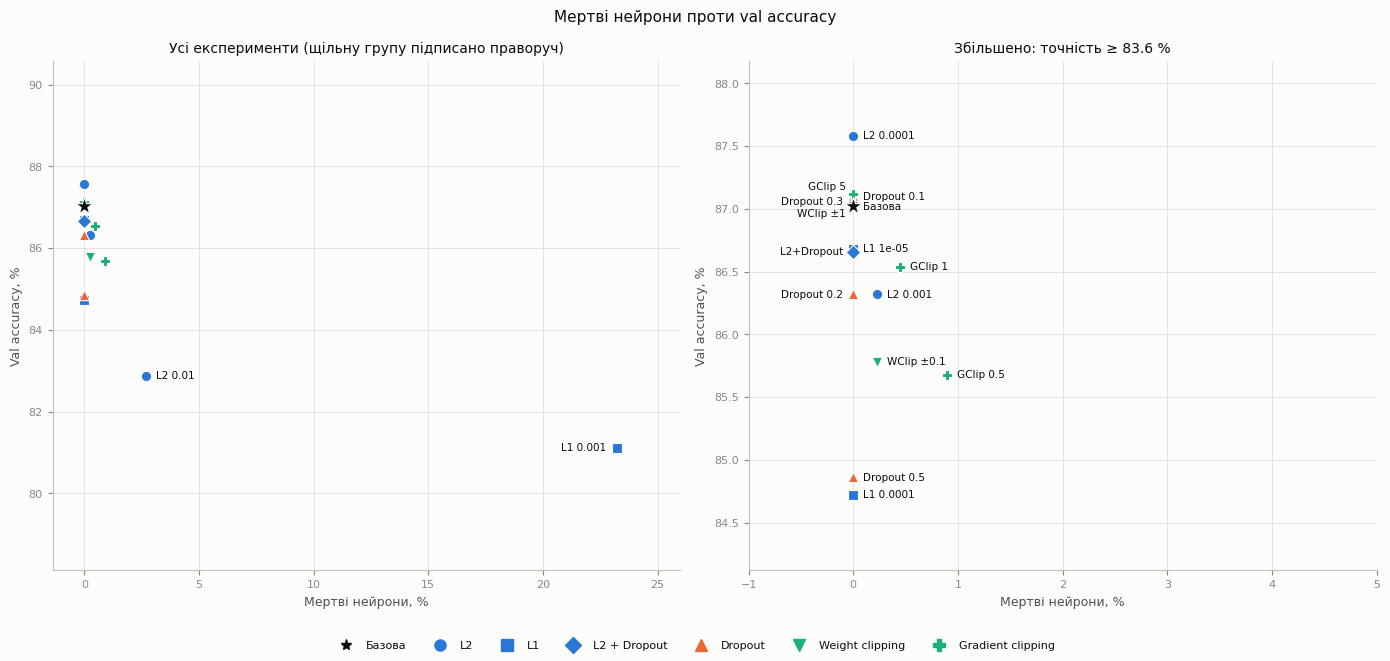

In [21]:
FAMILY_STYLE = {
    "Базова": (COLORS["ink"], "*"),
    "L2": (COLORS["train"], "o"),
    "L1": (COLORS["train"], "s"),
    "L2 + Dropout": (COLORS["train"], "D"),
    "Dropout": (COLORS["val"], "^"),
    "Weight clipping": (COLORS["third"], "v"),
    "Gradient clipping": (COLORS["third"], "P"),
}


def annotate_without_overlap(ax, xs, ys, labels, fontsize=7.5):
    """Простий жадібний розподіл підписів: кожен отримує найближче вільне місце навколо точки."""
    fig = ax.figure
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    points = ax.transData.transform(np.column_stack([xs, ys]))
    axes_box = ax.get_window_extent(renderer)
    to_points = 72 / fig.dpi
    angles = np.deg2rad([0, 180, 45, 135, 315, 225, 90, 270, 20, 160, 340, 200])
    radii = [10, 18, 28, 40, 55, 72, 92, 115, 140, 170, 205]
    placed = []

    def overlaps(a, b):
        return not (a[2] < b[0] or a[0] > b[2] or a[3] < b[1] or a[1] > b[3])

    point_boxes = [(x - 6, y - 6, x + 6, y + 6) for x, y in points]
    order = np.argsort(points[:, 0])
    for index in order:
        text = ax.text(0, 0, labels[index], fontsize=fontsize)
        box = text.get_window_extent(renderer)
        width, height = box.width, box.height
        text.remove()
        x, y = points[index]
        chosen = None
        for radius in radii:
            for angle in angles:
                dx, dy = radius * np.cos(angle), radius * np.sin(angle)
                left = x + dx if dx >= 0 else x + dx - width
                bottom = y + dy - height / 2
                candidate = (left, bottom, left + width, bottom + height)
                inside = (
                    candidate[0] >= axes_box.x0 + 2
                    and candidate[2] <= axes_box.x1 - 2
                    and candidate[1] >= axes_box.y0 + 2
                    and candidate[3] <= axes_box.y1 - 2
                )
                if inside and not any(overlaps(candidate, other) for other in placed + point_boxes):
                    chosen = (dx, dy, candidate)
                    break
            if chosen:
                break
        if chosen is None:
            chosen = (10, 0, (x + 10, y - height / 2, x + 10 + width, y + height / 2))
        dx, dy, candidate = chosen
        placed.append(candidate)
        ax.annotate(
            labels[index],
            xy=(xs[index], ys[index]),
            xytext=(dx * to_points, dy * to_points),
            textcoords="offset points",
            ha="left" if dx >= 0 else "right",
            va="center",
            fontsize=fontsize,
            color=COLORS["ink"],
            arrowprops=dict(arrowstyle="-", color=COLORS["muted"], linewidth=0.5, shrinkA=0, shrinkB=3) if np.hypot(dx, dy) > 20 else None,
        )


def scatter_panel(ax, runs, x_limits, y_limits, title, labeled=None):
    """Точки всіх запусків. labeled обмежує підписи, якщо щільну зону підписано на іншій панелі."""
    labeled = runs if labeled is None else labeled
    for run in runs:
        color, marker = FAMILY_STYLE[run["family"]]
        ax.scatter(run["dead_pct"], 100 * run["val_acc"], color=color, marker=marker, s=170 if marker == "*" else 55, edgecolors=COLORS["surface"], linewidths=0.8, zorder=4 if marker == "*" else 3)
    ax.set(xlim=x_limits, ylim=y_limits, title=title, xlabel="Мертві нейрони, %", ylabel="Val accuracy, %")
    annotate_without_overlap(ax, [r["dead_pct"] for r in labeled], [100 * r["val_acc"] for r in labeled], [r["label"] for r in labeled])


all_runs = list(RUNS.values())
best_acc = max(r["val_acc"] for r in all_runs)
zoom_floor = best_acc - 0.04
zoom_runs = [r for r in all_runs if r["val_acc"] >= zoom_floor]
needs_zoom = len(zoom_runs) < len(all_runs)

max_dead = max(r["dead_pct"] for r in all_runs)
x_limits = (-max(1.0, max_dead * 0.06), max(5.0, max_dead * 1.12))
all_acc = [100 * r["val_acc"] for r in all_runs]
fig, axes = plt.subplots(1, 2 if needs_zoom else 1, figsize=(14, 6.6) if needs_zoom else (10, 6.6), squeeze=False)
outside_zoom = [r for r in all_runs if r["val_acc"] < zoom_floor]
if needs_zoom:
    scatter_panel(axes[0, 0], all_runs, x_limits, (min(all_acc) - 3, max(all_acc) + 3), "Усі експерименти (щільну групу підписано праворуч)", labeled=outside_zoom)
else:
    scatter_panel(axes[0, 0], all_runs, x_limits, (min(all_acc) - 3, max(all_acc) + 3), "Усі експерименти")
if needs_zoom:
    zoom_dead = max(r["dead_pct"] for r in zoom_runs)
    zoom_acc = [100 * r["val_acc"] for r in zoom_runs]
    scatter_panel(axes[0, 1], zoom_runs, (-max(1.0, zoom_dead * 0.06), max(5.0, zoom_dead * 1.25)), (min(zoom_acc) - 0.6, max(zoom_acc) + 0.6), f"Збільшено: точність ≥ {100 * zoom_floor:.1f} %")

handles = [
    plt.Line2D([0], [0], linestyle="", marker=marker, color=color, markersize=8, label=family)
    for family, (color, marker) in FAMILY_STYLE.items()
]
fig.legend(handles=handles, loc="lower center", ncol=len(handles))
fig.suptitle("Мертві нейрони проти val accuracy", fontsize=11)
fig.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

In [22]:
def spearman(a, b):
    """Рангова кореляція Спірмена. Повертає NaN, якщо одна з величин стала."""
    a, b = pd.Series(a).rank(), pd.Series(b).rank()
    if a.std() == 0 or b.std() == 0:
        return float("nan")
    return float(a.corr(b))


def correlation_text(value):
    if np.isnan(value):
        return "обчислити неможливо, бо одна з величин стала"
    strength = "слабка" if abs(value) < 0.3 else "помірна" if abs(value) < 0.6 else "сильна"
    direction = "від'ємна" if value < 0 else "додатна"
    return f"{value:+.2f} ({strength} {direction})"


dead_values = summary["Dead neurons %"].to_numpy()
acc_values = summary["Val accuracy"].to_numpy()
sparsity_values = summary["Sparsity %"].to_numpy()
rho_dead_acc = spearman(dead_values, acc_values)
rho_sparse_dead = spearman(sparsity_values, dead_values)
rho_sparse_acc = spearman(sparsity_values, acc_values)

HIGH_DEAD = 10.0
high = summary[summary["Dead neurons %"] >= HIGH_DEAD]
low = summary[summary["Dead neurons %"] < HIGH_DEAD]
if len(high) == 0:
    many_dead = f"У жодному експерименті частка мертвих нейронів не сягнула {HIGH_DEAD:g} % (максимум {dead_values.max():.1f} %), тому ці дані не дають змоги судити про великі значення."
else:
    resilient = high[high["Val accuracy"] >= base["val_acc"] - NOISE]
    many_dead = (
        f"Моделей з часткою мертвих нейронів ≥ {HIGH_DEAD:g} %: {len(high)}, їхня середня val accuracy {100 * high['Val accuracy'].mean():.2f} %. "
        f"Решта ({len(low)}) мають у середньому {100 * low['Val accuracy'].mean():.2f} %. "
    )
    if len(resilient) > 0:
        many_dead += "Попри це, не гірші за базову в межах шуму: " + ", ".join(f"{row['Експеримент']} ({row['Dead neurons %']:.1f} % мертвих, {100 * row['Val accuracy']:.2f} %)" for _, row in resilient.iterrows()) + ". Отже, багато мертвих нейронів не завжди означає гіршу точність: мережа має запас ємності."
    else:
        many_dead += "Жодна з них не досягає базової точності в межах шуму, тому в цьому запуску багато мертвих нейронів супроводжується гіршою точністю. Проте це не доводить причинність: мертві нейрони й падіння точності можуть бути спільним наслідком занадто сильного штрафу."

# Пара з майже однаковою часткою мертвих нейронів і найбільшою різницею в точності
pair_best = None
records = summary.to_dict("records")
for i in range(len(records)):
    for j in range(i + 1, len(records)):
        if abs(records[i]["Dead neurons %"] - records[j]["Dead neurons %"]) <= 1.0:
            difference = abs(records[i]["Val accuracy"] - records[j]["Val accuracy"])
            if pair_best is None or difference > pair_best[0]:
                pair_best = (difference, records[i], records[j])
if pair_best and pair_best[0] > 2 * NOISE:
    same_dead = (
        f"Так. {pair_best[1]['Експеримент']} ({pair_best[1]['Dead neurons %']:.1f} % мертвих) має val accuracy {100 * pair_best[1]['Val accuracy']:.2f} %, "
        f"а {pair_best[2]['Експеримент']} ({pair_best[2]['Dead neurons %']:.1f} % мертвих) має {100 * pair_best[2]['Val accuracy']:.2f} %. "
        f"Різниця {100 * pair_best[0]:.2f} в.п. перевищує подвійний рівень шуму."
    )
elif pair_best:
    same_dead = f"У цьому запуску найбільша різниця точності між моделями з близькою часткою мертвих нейронів (різниця до 1 в.п.) становить лише {100 * pair_best[0]:.2f} в.п., це в межах подвійного рівня шуму. Теоретично така ситуація можлива, але ці дані її не підтверджують."
else:
    same_dead = "У цьому запуску немає пар моделей з близькою часткою мертвих нейронів."

sparse_alive = summary[(summary["Sparsity %"] >= base["sparsity_pct"] + 10) & (summary["Dead neurons %"] <= base["dead_pct"] + 2) & (summary["Val accuracy"] >= base["val_acc"] - NOISE)]
sparse_dead = summary[(summary["Sparsity %"] >= base["sparsity_pct"] + 10) & (summary["Dead neurons %"] > base["dead_pct"] + 2)]
balance_parts = [f"Рангова кореляція між sparsity і часткою мертвих нейронів: {correlation_text(rho_sparse_dead)}, між sparsity і val accuracy: {correlation_text(rho_sparse_acc)}."]
if len(sparse_alive):
    balance_parts.append("Висока sparsity без зростання мертвих нейронів і без втрати точності (корисний баланс): " + ", ".join(sparse_alive["Експеримент"]) + ".")
if len(sparse_dead):
    balance_parts.append("Висока sparsity разом зі зростанням мертвих нейронів: " + ", ".join(f"{row['Експеримент']} ({row['Sparsity %']:.1f} % малих ваг, {row['Dead neurons %']:.1f} % мертвих, accuracy {100 * row['Val accuracy']:.2f} %)" for _, row in sparse_dead.iterrows()) + ".")
if not len(sparse_alive) and not len(sparse_dead):
    balance_parts.append("Жодна модель не перевищила базову sparsity більш ніж на 10 в.п.")

md(
    f"""**Відповіді за фактичними числами** (усього {len(summary)} експериментів, один seed).

**Чи є залежність?** Рангова кореляція Спірмена між часткою мертвих нейронів і val accuracy: {correlation_text(rho_dead_acc)}. Кореляція показує лише зв'язок, а не причину.

**Чи багато мертвих нейронів означає гіршу точність?** {many_dead}

**Чи можуть моделі з однаковою кількістю мертвих нейронів мати різну точність?** {same_dead} Сама кількість мертвих нейронів не описує, як використані живі нейрони.

**Чи є баланс між sparsity і мертвими нейронами?** {" ".join(balance_parts)}"""
)

**Відповіді за фактичними числами** (усього 17 експериментів, один seed).

**Чи є залежність?** Рангова кореляція Спірмена між часткою мертвих нейронів і val accuracy: -0.64 (сильна від'ємна). Кореляція показує лише зв'язок, а не причину.

**Чи багато мертвих нейронів означає гіршу точність?** Моделей з часткою мертвих нейронів ≥ 10 %: 1, їхня середня val accuracy 81.12 %. Решта (16) мають у середньому 86.21 %. Жодна з них не досягає базової точності в межах шуму, тому в цьому запуску багато мертвих нейронів супроводжується гіршою точністю. Проте це не доводить причинність: мертві нейрони й падіння точності можуть бути спільним наслідком занадто сильного штрафу.

**Чи можуть моделі з однаковою кількістю мертвих нейронів мати різну точність?** Так. L2 λ2=0.0001 (0.0 % мертвих) має val accuracy 87.58 %, а L1 λ1=0.0001 (0.0 % мертвих) має 84.72 %. Різниця 2.86 в.п. перевищує подвійний рівень шуму. Сама кількість мертвих нейронів не описує, як використані живі нейрони.

**Чи є баланс між sparsity і мертвими нейронами?** Рангова кореляція між sparsity і часткою мертвих нейронів: +0.52 (помірна додатна), між sparsity і val accuracy: -0.59 (помірна від'ємна). Висока sparsity разом зі зростанням мертвих нейронів: L2 λ2=0.01 (75.3 % малих ваг, 2.7 % мертвих, accuracy 82.88 %), L1 λ1=0.001 (98.8 % малих ваг, 23.2 % мертвих, accuracy 81.12 %).

### 5.4. Перенавчання і недонавчання: слабка проти сильної регуляризації

Ліворуч у кожному рядку найслабше значення параметра, праворуч найсильніше. Ознака **перенавчання**: train accuracy далі зростає, а validation виходить на плато, тобто розрив збільшується. Ознака **недонавчання**: обидві криві близько одна до одної, але нижче, ніж у базової моделі.

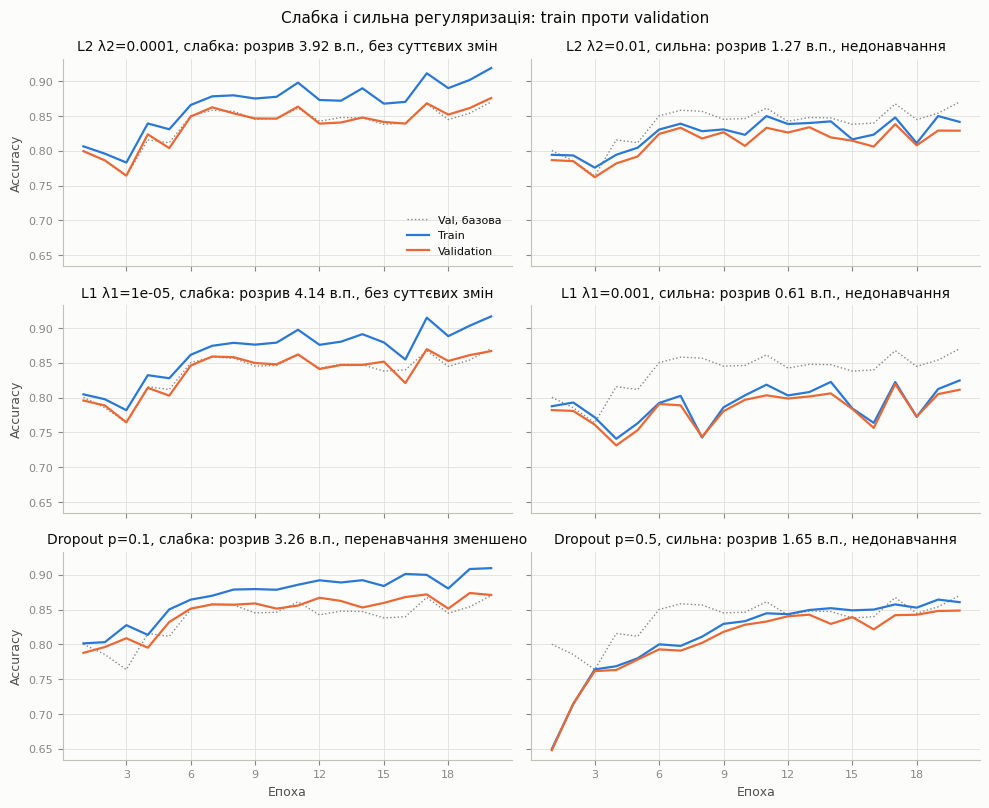

In [23]:
weak_strong_rows = [("L2", L2_NAMES), ("L1", L1_NAMES), ("Dropout", DROPOUT_NAMES)]
fig, axes = plt.subplots(len(weak_strong_rows), 2, figsize=(10, 8.2), sharex=True, sharey=True)
for row, (family, names) in enumerate(weak_strong_rows):
    for column, (strength_label, name) in enumerate((("слабка", names[0]), ("сильна", names[-1]))):
        ax = axes[row, column]
        run = RUNS[name]
        epochs_axis = np.arange(1, len(run["history"]["train_acc"]) + 1)
        ax.plot(epochs_axis, RUNS[BASE]["history"]["val_acc"], color=COLORS["muted"], linewidth=1, linestyle=":", label="Val, базова")
        ax.plot(epochs_axis, run["history"]["train_acc"], color=COLORS["train"], label="Train")
        ax.plot(epochs_axis, run["history"]["val_acc"], color=COLORS["val"], label="Validation")
        gap = run["train_acc5"] - run["val_acc5"]
        ax.set_title(f"{name}, {strength_label}: розрив {100 * gap:.2f} в.п., {diagnose(run)}")
        if column == 0:
            ax.set_ylabel("Accuracy")
        if row == len(weak_strong_rows) - 1:
            ax.set_xlabel("Епоха")
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
axes[0, 0].legend(loc="lower right")
fig.suptitle("Слабка і сильна регуляризація: train проти validation", fontsize=11)
fig.tight_layout()
plt.show()

### 5.5. Точність за класами і типові помилки

Загальна accuracy не показує, які саме класи модель розрізняє добре, а які плутає. Тут порівнюються базова модель і модель з найкращою середньою val accuracy за 5 останніх епох. Усі показники рахуються на фінальних вагах і на валідаційній вибірці.

- **Матриця плутанини:** рядок означає істинний клас, стовпець означає прогноз, значення є відсотком від прикладів істинного класу. Діагональ показує правильні відповіді, а все поза нею є помилками.
- **Precision:** яка частка прогнозів цього класу правильна. **Recall:** яка частка прикладів цього класу знайдена. **F1:** їх гармонійне середнє.
- **Впевненість проти точності:** якщо модель каже «90 %», то вона має бути правою приблизно у 90 % таких випадків. Точки нижче діагоналі означають надмірну впевненість.
- **ECE (Expected Calibration Error):** середня за кількістю прикладів різниця між впевненістю і точністю. Чим менше, тим надійніше можна покладатися на ймовірності моделі.
- **Приклади помилок:** зображення, на яких модель помилилася з найбільшою впевненістю. Вони допомагають зрозуміти, чи помилка зрозуміла й людині.

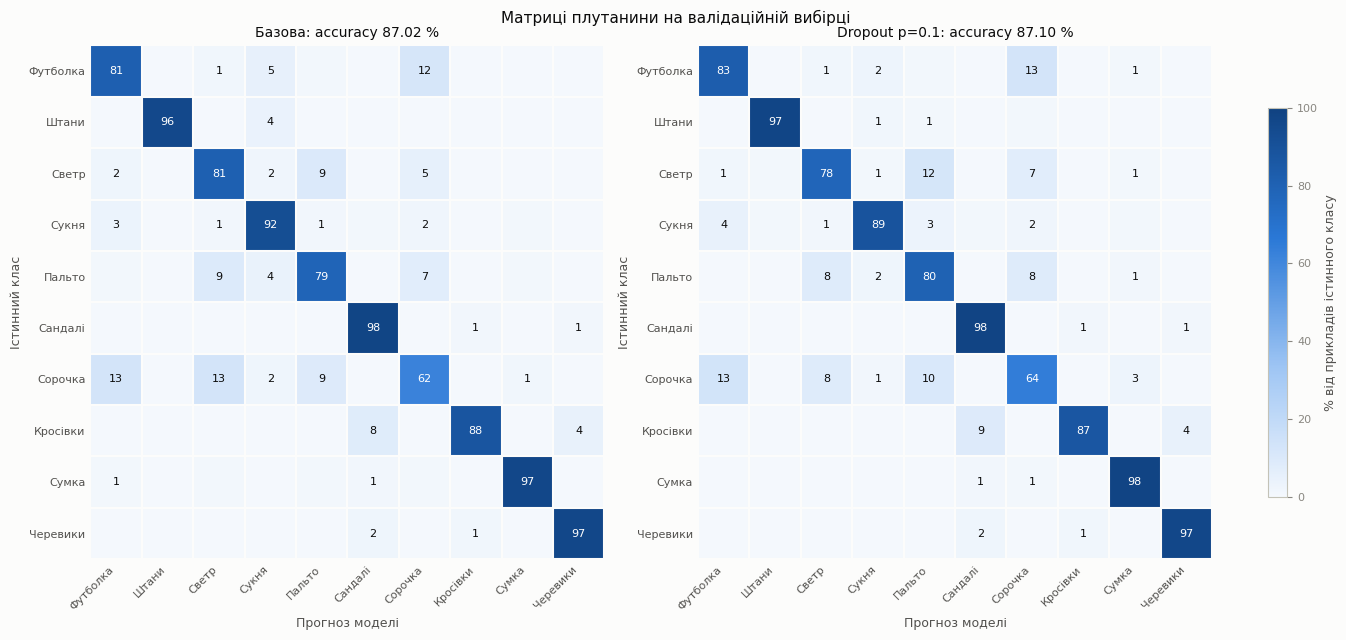

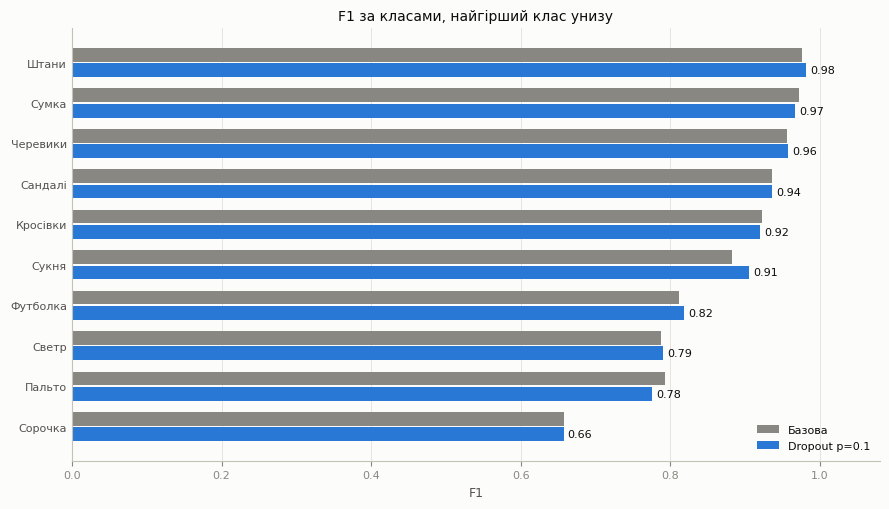

Показники за класами: Dropout p=0.1


Клас,Прикладів,Precision,Recall,F1
Сорочка,500,0.673,0.642,0.657
Пальто,500,0.754,0.798,0.776
Светр,500,0.802,0.778,0.790
Футболка,500,0.810,0.826,0.818
Сукня,500,0.921,0.890,0.905
Кросівки,500,0.975,0.870,0.920
Сандалі,500,0.891,0.984,0.935
Черевики,500,0.949,0.966,0.957
Сумка,500,0.952,0.982,0.967
Штани,500,0.988,0.974,0.981


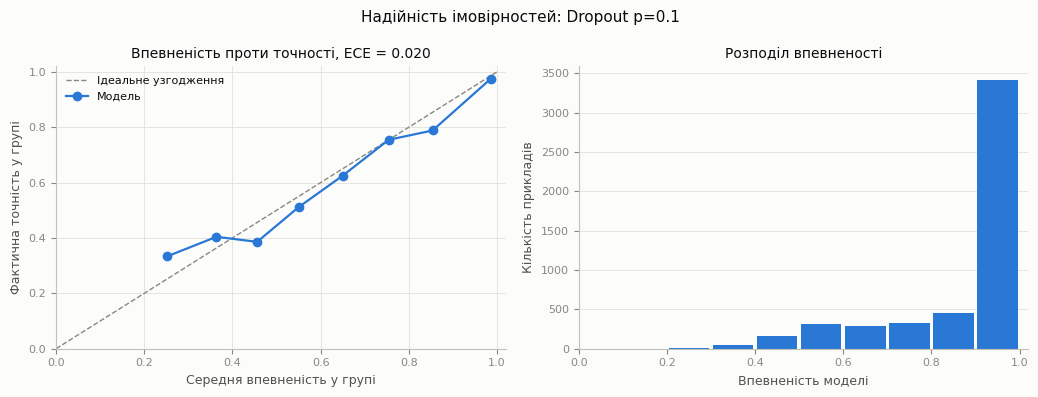

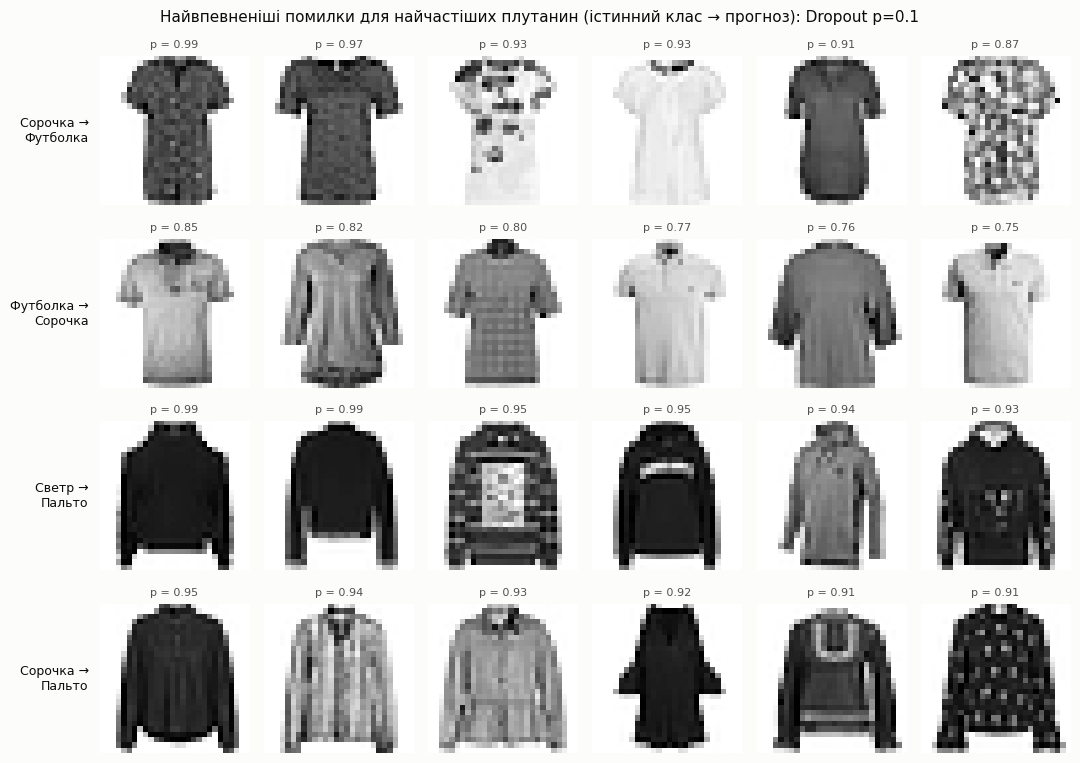

In [24]:
BEST_NAME = best_mean_row["Експеримент"]
CM_NAMES = [BASE] if BEST_NAME == BASE else [BASE, BEST_NAME]
N_CLASSES = len(CLASS_NAMES)
CM_CMAP = LinearSegmentedColormap.from_list("sequential_blue", ["#f4f8fd", "#9ec5f4", "#2a78d6", "#104281"])


def class_report(probabilities, y_true):
    """Матриця плутанини і precision / recall / F1 для кожного класу."""
    y_pred = probabilities.argmax(axis=1)
    matrix = np.zeros((N_CLASSES, N_CLASSES), dtype=np.int64)
    np.add.at(matrix, (y_true, y_pred), 1)
    correct = np.diag(matrix)
    recall = correct / np.maximum(matrix.sum(axis=1), 1)
    precision = correct / np.maximum(matrix.sum(axis=0), 1)
    f1 = 2 * precision * recall / np.maximum(precision + recall, 1e-12)
    return {
        "probabilities": probabilities,
        "y_pred": y_pred,
        "matrix": matrix,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "accuracy": float(correct.sum() / matrix.sum()),
    }


REPORTS = {name: class_report(RUNS[name]["model"].predict_proba(X_val), y_val) for name in CM_NAMES}
best_report = REPORTS[BEST_NAME]
base_report = REPORTS[BASE]

# Матриці плутанини
fig, axes = plt.subplots(1, len(CM_NAMES), figsize=(6.2 * len(CM_NAMES) + 1.0, 6.2), squeeze=False, layout="constrained")
for ax, name in zip(axes[0], CM_NAMES):
    report = REPORTS[name]
    shares = 100 * report["matrix"] / np.maximum(report["matrix"].sum(axis=1, keepdims=True), 1)
    image = ax.imshow(shares, cmap=CM_CMAP, vmin=0, vmax=100)
    for row in range(N_CLASSES):
        for column in range(N_CLASSES):
            value = shares[row, column]
            if round(value) > 0:
                ink = "#ffffff" if value >= 50 else COLORS["ink"]
                ax.text(column, row, f"{value:.0f}", ha="center", va="center", fontsize=8, color=ink)
    ax.set_xticks(range(N_CLASSES), CLASS_NAMES, rotation=45, ha="right")
    ax.set_yticks(range(N_CLASSES), CLASS_NAMES)
    ax.tick_params(colors=COLORS["secondary"], length=0)
    ax.set_xticks(np.arange(N_CLASSES + 1) - 0.5, minor=True)
    ax.set_yticks(np.arange(N_CLASSES + 1) - 0.5, minor=True)
    ax.grid(False)
    ax.grid(which="minor", color=COLORS["surface"], linewidth=1.5)
    ax.tick_params(which="minor", length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.set(xlabel="Прогноз моделі", ylabel="Істинний клас", title=f"{name}: accuracy {pct(report['accuracy'])}")
fig.colorbar(image, ax=axes.ravel().tolist(), shrink=0.75, label="% від прикладів істинного класу")
fig.suptitle("Матриці плутанини на валідаційній вибірці", fontsize=11)
plt.show()

# F1 за класами
order = np.argsort(best_report["f1"])
positions = np.arange(N_CLASSES)
fig, ax = plt.subplots(figsize=(9, 5.2))
if BEST_NAME == BASE:
    bars = ax.barh(positions, best_report["f1"][order], height=0.65, color=COLORS["train"])
else:
    ax.barh(positions + 0.19, base_report["f1"][order], height=0.34, color=COLORS["muted"], label=BASE)
    bars = ax.barh(positions - 0.19, best_report["f1"][order], height=0.34, color=COLORS["train"], label=BEST_NAME)
    ax.legend(loc="lower right")
ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=8, color=COLORS["ink"])
ax.set_yticks(positions, [CLASS_NAMES[i] for i in order])
ax.tick_params(axis="y", colors=COLORS["secondary"], length=0)
ax.set(xlim=(0, 1.08), xlabel="F1", title="F1 за класами, найгірший клас унизу")
ax.grid(False, axis="y")
fig.tight_layout()
plt.show()

class_table = pd.DataFrame(
    {
        "Клас": CLASS_NAMES,
        "Прикладів": best_report["matrix"].sum(axis=1),
        "Precision": best_report["precision"],
        "Recall": best_report["recall"],
        "F1": best_report["f1"],
    }
).sort_values("F1")
print(f"Показники за класами: {BEST_NAME}")
display(class_table.style.hide(axis="index").format({"Precision": "{:.3f}", "Recall": "{:.3f}", "F1": "{:.3f}"}))

# Впевненість проти точності
confidence = best_report["probabilities"].max(axis=1)
is_correct = best_report["y_pred"] == y_val
bin_edges = np.linspace(0.1, 1.0, 10)
bin_index = np.clip(np.digitize(confidence, bin_edges) - 1, 0, len(bin_edges) - 2)
bin_rows = []
for index in range(len(bin_edges) - 1):
    selected = bin_index == index
    if selected.any():
        bin_rows.append((float(confidence[selected].mean()), float(is_correct[selected].mean()), int(selected.sum())))
mean_confidence, bin_accuracy, bin_counts = map(np.array, zip(*bin_rows))
ece = float(np.sum(bin_counts * np.abs(mean_confidence - bin_accuracy)) / confidence.size)

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4))
axes[0].plot([0, 1], [0, 1], color=COLORS["muted"], linewidth=1, linestyle="--", label="Ідеальне узгодження")
axes[0].plot(mean_confidence, bin_accuracy, color=COLORS["train"], marker="o", markersize=6, label="Модель")
axes[0].set(xlim=(0, 1.02), ylim=(0, 1.02), xlabel="Середня впевненість у групі", ylabel="Фактична точність у групі", title=f"Впевненість проти точності, ECE = {ece:.3f}")
axes[0].legend(loc="upper left")
widths = np.diff(bin_edges) * 0.92
axes[1].bar(bin_edges[:-1] + np.diff(bin_edges) / 2, np.histogram(confidence, bins=bin_edges)[0], width=widths, color=COLORS["train"])
axes[1].set(xlim=(0, 1.02), xlabel="Впевненість моделі", ylabel="Кількість прикладів", title="Розподіл впевненості")
axes[1].grid(False, axis="x")
fig.suptitle(f"Надійність імовірностей: {BEST_NAME}", fontsize=11)
fig.tight_layout()
plt.show()

# Найчастіші плутанини і найвпевненіші помилки
errors_only = best_report["matrix"].copy()
np.fill_diagonal(errors_only, 0)
pair_order = np.argsort(errors_only, axis=None)[::-1]
top_pairs = [tuple(int(v) for v in np.unravel_index(i, errors_only.shape)) for i in pair_order[:4]]
top_pairs = [pair for pair in top_pairs if errors_only[pair] > 0]

N_EXAMPLES = 6
if top_pairs:
    fig, axes = plt.subplots(len(top_pairs), N_EXAMPLES, figsize=(1.55 * N_EXAMPLES + 1.6, 1.95 * len(top_pairs)), squeeze=False)
    for row, (true_class, predicted_class) in enumerate(top_pairs):
        indices = np.flatnonzero((y_val == true_class) & (best_report["y_pred"] == predicted_class))
        indices = indices[np.argsort(confidence[indices])[::-1]][:N_EXAMPLES]
        for column in range(N_EXAMPLES):
            ax = axes[row, column]
            ax.set_xticks([])
            ax.set_yticks([])
            ax.grid(False)
            for spine in ax.spines.values():
                spine.set_visible(False)
            if column < len(indices):
                ax.imshow(X_val[indices[column]].reshape(28, 28), cmap="Greys")
                ax.set_title(f"p = {confidence[indices[column]]:.2f}", fontsize=8, color=COLORS["secondary"])
        axes[row, 0].set_ylabel(f"{CLASS_NAMES[true_class]} →\n{CLASS_NAMES[predicted_class]}", rotation=0, ha="right", va="center", labelpad=8, fontsize=9, color=COLORS["ink"])
    fig.suptitle(f"Найвпевненіші помилки для найчастіших плутанин (істинний клас → прогноз): {BEST_NAME}", fontsize=11)
    fig.tight_layout()
    plt.show()

In [25]:
hardest = int(np.argmin(best_report["recall"]))
easiest = int(np.argmax(best_report["recall"]))
n_errors = int(errors_only.sum())
pair_lines = [
    f"- {CLASS_NAMES[t]} → {CLASS_NAMES[p]}: кількість помилок {int(errors_only[t, p])}, це {100 * errors_only[t, p] / max(best_report['matrix'][t].sum(), 1):.1f} % прикладів класу «{CLASS_NAMES[t]}»."
    for t, p in top_pairs
]
top_share = sum(int(errors_only[pair]) for pair in top_pairs) / max(n_errors, 1)

gap_confidence = float(confidence.mean() - is_correct.mean())
if abs(gap_confidence) < 0.01:
    calibration_text = "Середня впевненість майже збігається з фактичною точністю"
elif gap_confidence > 0:
    calibration_text = "Модель загалом надто впевнена в собі"
else:
    calibration_text = "Модель загалом надто обережна"

# Похибка recall одного класу приблизно ±1 ст. відхилення на його прикладах
class_noise = float(np.sqrt(best_report["accuracy"] * (1 - best_report["accuracy"]) / (N_VAL / N_CLASSES)))
if BEST_NAME == BASE:
    change_text = "Найкращою за середнім виявилася сама базова модель, тому порівняння за класами немає."
else:
    recall_change = best_report["recall"] - base_report["recall"]
    notable = [i for i in range(N_CLASSES) if abs(recall_change[i]) > 2 * class_noise]
    if notable:
        change_text = f"Відносно базової моделі recall змінився понад подвійну похибку класу (±{200 * class_noise:.1f} в.п.) у таких класах: " + ", ".join(f"{CLASS_NAMES[i]} ({100 * recall_change[i]:+.1f} в.п.)" for i in notable) + "."
    else:
        change_text = f"Відносно базової моделі recall жодного класу не змінився понад подвійну похибку класу (±{200 * class_noise:.1f} в.п.), тож різниці за класами не варто інтерпретувати."

md(
    "\n".join(
        [
            f"**Що показують дані** (модель {BEST_NAME}, accuracy на фінальній епосі {pct(best_report['accuracy'])}).",
            "",
            f"**Найлегший і найважчий клас.** Найкращий recall у класу «{CLASS_NAMES[easiest]}» ({pct(best_report['recall'][easiest], 1)}), найгірший у класу «{CLASS_NAMES[hardest]}» ({pct(best_report['recall'][hardest], 1)}).",
            "",
            f"**Найчастіші плутанини.** Перелічені нижче пари дають {100 * top_share:.0f} % усіх помилок (всього помилок: {n_errors}):",
            "",
            *pair_lines,
            "",
            f"**Надійність імовірностей.** Середня впевненість {pct(confidence.mean(), 1)}, фактична точність {pct(is_correct.mean(), 1)}, ECE = {ece:.3f}. {calibration_text}.",
            "",
            f"**Порівняння з базовою моделлю.** {change_text}",
        ]
    )
)

**Що показують дані** (модель Dropout p=0.1, accuracy на фінальній епосі 87.10 %).

**Найлегший і найважчий клас.** Найкращий recall у класу «Сандалі» (98.4 %), найгірший у класу «Сорочка» (64.2 %).

**Найчастіші плутанини.** Перелічені нижче пари дають 37 % усіх помилок (всього помилок: 645):

- Сорочка → Футболка: кількість помилок 66, це 13.2 % прикладів класу «Сорочка».
- Футболка → Сорочка: кількість помилок 63, це 12.6 % прикладів класу «Футболка».
- Светр → Пальто: кількість помилок 59, це 11.8 % прикладів класу «Светр».
- Сорочка → Пальто: кількість помилок 51, це 10.2 % прикладів класу «Сорочка».

**Надійність імовірностей.** Середня впевненість 89.0 %, фактична точність 87.1 %, ECE = 0.020. Модель загалом надто впевнена в собі.

**Порівняння з базовою моделлю.** Відносно базової моделі recall змінився понад подвійну похибку класу (±3.0 в.п.) у таких класах: Светр (-3.2 в.п.), Сукня (-3.2 в.п.).

### 5.6. Висновки

Числа нижче згенеровані кодом з таблиці поточного запуску. Під ними наведено визначення понять, які не залежать від результатів.

In [26]:
def family_line(family, names, strength_note):
    """Описує зміну точності зі зростанням сили одного методу."""
    chain = [(BASE, RUNS[BASE])] + [(n, RUNS[n]) for n in names]
    accuracy = [run["val_acc5"] for _, run in chain]
    best_index = int(np.argmax(accuracy))
    values = " → ".join(f"{pct(a)}" for a in accuracy)
    loss_from_best = accuracy[best_index] - accuracy[-1]
    if best_index == 0:
        peak = "найкращою лишилася базова модель без цього методу"
    elif best_index == len(chain) - 1:
        peak = "найкраще значення припало на найсильніший варіант"
    else:
        peak = f"оптимум припав на проміжний варіант {chain[best_index][0]}"
    return f"- **{family}** ({strength_note}): {values}. Тут {peak}; найсильніший варіант програє найкращому {100 * loss_from_best:.2f} в.п.", loss_from_best


family_results = [
    family_line("L2", L2_NAMES, "λ2 = 0, " + ", ".join(f"{v:g}" for v in L2_VALUES)),
    family_line("L1", L1_NAMES, "λ1 = 0, " + ", ".join(f"{v:g}" for v in L1_VALUES)),
    family_line("Dropout", DROPOUT_NAMES, "p = 0, " + ", ".join(f"{v:g}" for v in DROPOUT_VALUES)),
    family_line("Gradient clipping", list(reversed(GCLIP_NAMES)), "без обрізання, c = " + ", ".join(f"{v:g}" for v in reversed(GRAD_CLIP_VALUES))),
]
worst_drop = max(result[1] for result in family_results)
if worst_drop > NOISE_MEAN:
    general_answer = f"**Ні, не завжди.** У цьому запуску найсильніший варіант програє найкращому варіанту того ж методу до {100 * worst_drop:.2f} в.п., що перевищує рівень шуму (±{100 * NOISE_MEAN:.2f} в.п.)."
else:
    general_answer = f"**У цьому запуску падіння за посилення регуляризації не перевищило рівень шуму** (±{100 * NOISE_MEAN:.2f} в.п.), тож дані не показують шкоди, але й не доводять, що подальше посилення було б безпечним: для цього потрібні сильніші значення."

reduced = summary[summary["Діагноз"] == "перенавчання зменшено"]
underfit = summary[summary["Діагноз"].isin(["недонавчання", "колапс"])]
traded = summary[summary["Діагноз"] == "менший розрив ціною точності"]
neutral = summary[summary["Діагноз"] == "без суттєвих змін"]


def run_list(frame):
    if len(frame) == 0:
        return "таких моделей у цьому запуску немає"
    return "; ".join(
        f"{row['Експеримент']} (train {100 * row['Train acc, сер. 5 епох']:.2f} %, val {100 * row['Val acc, сер. 5 епох']:.2f} %, розрив {100 * row['Розрив, сер. 5 епох']:.2f} в.п.)"
        for _, row in frame.iterrows()
    )


md(
    "\n".join(
        [
            "#### Чи завжди збільшення сили регуляризації покращує узагальнювальну здатність?",
            "",
            general_answer,
            "",
            "Усі accuracy у цьому розділі є середніми за останні 5 епох, бо фінальна епоха залежить від випадкового стрибка. Значення фінальної епохи є в зведеній таблиці.",
            "",
            "Val accuracy за зростання сили методу (перше значення є базовою моделлю):",
            "",
            *[result[0] for result in family_results],
            "",
            "#### Коли регуляризація зменшує перенавчання",
            "",
            f"Базова модель: train {pct(base['train_acc5'])}, val {pct(base['val_acc5'])}, розрив {100 * base_gap:.2f} в.п. Мінімум її val loss {base['best_val_loss']:.4f} припав на епоху {base['best_val_loss_epoch']} з {len(base['history']['val_loss'])}, наприкінці val loss становить {base['val_loss']:.4f}.",
            "",
            f"Розрив зменшився без втрати точності понад шум: {run_list(reduced)}.",
            "",
            "#### Коли регуляризація спричиняє недонавчання",
            "",
            f"І train, і val accuracy помітно нижчі за базові: {run_list(underfit)}.",
            "",
            f"Проміжний випадок, де розрив менший, але val accuracy нижча понад шум: {run_list(traded)}.",
            "",
            "#### Без суттєвих змін",
            "",
            f"{run_list(neutral)}.",
            "",
            f"**Обмеження висновків.** Використано один seed і одну валідаційну вибірку з {N_VAL} прикладів, тому різниці середніх до приблизно {100 * NOISE_MEAN:.1f}–{200 * NOISE_MEAN:.1f} в.п. не варто вважати значущими, а для окремої фінальної епохи цей поріг ще вищий (±{100 * NOISE:.1f} в.п.). Для надійнішого порівняння варто повторити експерименти з кількома seed. Параметри вибиралися за цією ж вибіркою, тому найкращі значення можуть бути трохи завищені.",
        ]
    )
)

total_minutes = (time.time() - NOTEBOOK_START) / 60
print(f"Фактичний час виконання ноутбука: {total_minutes:.1f} хв")
if total_minutes > 30:
    print("Понад 30 хв: зменшіть EPOCHS (наприклад, до 12) або N_TRAIN (наприклад, до 10 000)")

#### Чи завжди збільшення сили регуляризації покращує узагальнювальну здатність?

**Ні, не завжди.** У цьому запуску найсильніший варіант програє найкращому варіанту того ж методу до 6.23 в.п., що перевищує рівень шуму (±0.54 в.п.).

Усі accuracy у цьому розділі є середніми за останні 5 епох, бо фінальна епоха залежить від випадкового стрибка. Значення фінальної епохи є в зведеній таблиці.

Val accuracy за зростання сили методу (перше значення є базовою моделлю):

- **L2** (λ2 = 0, 0.0001, 0.001, 0.01): 85.52 % → 85.93 % → 84.87 % → 82.20 %. Тут оптимум припав на проміжний варіант L2 λ2=0.0001; найсильніший варіант програє найкращому 3.73 в.п.
- **L1** (λ1 = 0, 1e-05, 0.0001, 0.001): 85.52 % → 85.42 % → 84.80 % → 79.29 %. Тут найкращою лишилася базова модель без цього методу; найсильніший варіант програє найкращому 6.23 в.п.
- **Dropout** (p = 0, 0.1, 0.3, 0.5): 85.52 % → 86.72 % → 86.05 % → 84.06 %. Тут оптимум припав на проміжний варіант Dropout p=0.1; найсильніший варіант програє найкращому 2.66 в.п.
- **Gradient clipping** (без обрізання, c = 5, 1, 0.5): 85.52 % → 85.65 % → 86.04 % → 85.24 %. Тут оптимум припав на проміжний варіант GClip c=1; найсильніший варіант програє найкращому 0.80 в.п.

#### Коли регуляризація зменшує перенавчання

Базова модель: train 89.90 %, val 85.52 %, розрив 4.38 в.п. Мінімум її val loss 0.3621 припав на епоху 20 з 20, наприкінці val loss становить 0.3621.

Розрив зменшився без втрати точності понад шум: Dropout p=0.1 (train 89.98 %, val 86.72 %, розрив 3.26 в.п.); Dropout p=0.3 (train 88.55 %, val 86.05 %, розрив 2.50 в.п.); GClip c=0.5 (train 87.26 %, val 85.24 %, розрив 2.02 в.п.); GClip c=1 (train 89.31 %, val 86.04 %, розрив 3.27 в.п.); Dropout p=0.2 (контроль) (train 89.34 %, val 86.30 %, розрив 3.04 в.п.); L2+Dropout (λ2=0.0001, p=0.2) (train 89.47 %, val 86.54 %, розрив 2.94 в.п.).

#### Коли регуляризація спричиняє недонавчання

І train, і val accuracy помітно нижчі за базові: L2 λ2=0.01 (train 83.47 %, val 82.20 %, розрив 1.27 в.п.); L1 λ1=0.001 (train 79.90 %, val 79.29 %, розрив 0.61 в.п.); Dropout p=0.5 (train 85.70 %, val 84.06 %, розрив 1.65 в.п.); WClip ±0.1 (дод.) (train 85.28 %, val 83.62 %, розрив 1.67 в.п.).

Проміжний випадок, де розрив менший, але val accuracy нижча понад шум: L1 λ1=0.0001 (train 88.05 %, val 84.80 %, розрив 3.25 в.п.).

#### Без суттєвих змін

L2 λ2=0.0001 (train 89.84 %, val 85.93 %, розрив 3.92 в.п.); L2 λ2=0.001 (train 88.45 %, val 84.87 %, розрив 3.58 в.п.); L1 λ1=1e-05 (train 89.55 %, val 85.42 %, розрив 4.14 в.п.); WClip ±1 (train 89.90 %, val 85.52 %, розрив 4.38 в.п.); GClip c=5 (train 90.01 %, val 85.65 %, розрив 4.36 в.п.).

**Обмеження висновків.** Використано один seed і одну валідаційну вибірку з 5000 прикладів, тому різниці середніх до приблизно 0.5–1.1 в.п. не варто вважати значущими, а для окремої фінальної епохи цей поріг ще вищий (±1.2 в.п.). Для надійнішого порівняння варто повторити експерименти з кількома seed. Параметри вибиралися за цією ж вибіркою, тому найкращі значення можуть бути трохи завищені.

Фактичний час виконання ноутбука: 18.5 хв


#### Різниця між поняттями

**Мала вага** — вага з невеликою абсолютною величиною, яка все ж передає сигнал. Це типовий наслідок L2. Сама по собі вона не означає, що зв'язок марний: багато малих ваг разом можуть давати значний внесок.

**Нульова або майже нульова вага** — вага, для якої |W| менше за вибраний поріг (тут 0.01). Вона практично вимикає один окремий зв'язок, але не цілий нейрон. Це типовий наслідок L1 і саме це вимірює sparsity. За SGD точний нуль трапляється рідко, тому використовується поріг.

**Неактивний нейрон** — нейрон, у якого на конкретному об'єкті Z ≤ 0, тож його вихід дорівнює нулю. Це нормальна робота ReLU: нейрон активний на одних об'єктах і вимкнений на інших. Така поведінка залежить від об'єкта і є зворотною.

**Мертвий нейрон** — нейрон, неактивний на **всіх** об'єктах вибірки: max Z ≤ 0. Похідна ReLU для нього всюди нульова, тому він не отримує градієнта від функції втрат і зазвичай не може відновитися самостійно. Це властивість нейрона на всій вибірці, а не окремого об'єкта. Для тих самих ваг нейрон може бути мертвим на тренувальній вибірці, але активним на новому об'єкті, тому тут важливо, на якій вибірці він вимірюється.

**Надмірно регуляризована модель** — модель, у якої обмеження настільки сильні, що вона не може вивчити навіть тренувальні дані: train accuracy помітно нижча, ніж без регуляризації, розрив train−val малий, а val accuracy теж низька. Малий розрив сам по собі не є успіхом: важливо, щоб він зменшувався без падіння val accuracy. Надмірна регуляризація може проявитися і без мертвих нейронів, наприклад, коли всі ваги дуже малі, але нейрони формально лишаються живими.